# Linear Regression — Grading Rubric

**Total: 100 points** — Theory **40 pts** (Sections 1–2) + Implementation **60 pts** (Section 3).

| # | Question | Points |
|---|----------|:------:|
| **Section 1 — Linear Algebra** | | **32** |
| P1 | Expand the cost | 3 |
| P2 | Compute $X^\top X$; it is the Hessian | 4 |
| P3 | The quadratic form and positive definiteness | 5 |
| P4 | See it in 3D: bowl vs. saddle | 4 |
| P5 | Normal equations and the solution | 4 |
| P6 | A diagonal $X^\top X$ decouples the features | 4 |
| P7 | Ridge regularization | 5 |
| P8 | Intercept-only regression: the best constant is the mean | 3 |
| **Section 2 — Probabilistic View** | | **8** |
| — | Gaussian likelihood, prior, MAP ⇒ ridge (parts a–e) | 8 |
| **Section 3 — Implementation** | | **60** |
| Q1 | One Feature Gradient Descent — Summation | 8 |
| Q2 | Linear Regression Gradient Descent — Vector | 6 |
| Q3 | Learning Rate Selection | 5 |
| Q4 | Normal Equation | 5 |
| Q5 | Two Feature Gradient Descent & Normalization | 7 |
| Q6 | Non-Linear Regression | 7 |
| Q7 | Regularized Linear Regression | 7 |
| Q8 | Regularization Parameter Selection | 5 |
| Q9 | Locally Weighted Linear Regression | 6 |
| Q10 | Bandwidth Parameter Selection | 4 |
| | **Total** | **100** |

# Section 1 — Linear Algebra Behind Linear Regression  ·  *32 pts*

> **Theme.** Every object in this section comes from *one* place: the linear-regression
> cost. The symmetric matrix you analyze is nothing mysterious — it is $X^\top X$, the Hessian of that cost. We start from the regression problem, differentiate
> it, and watch the quadratic form, positive definiteness, the normal equations,
> whitening, and regularization all fall out.

## Setup — fitting a line to 5 points

The first column of $X$ is all ones (the **intercept**, matching the programming
assignment); the second column holds the input values $x^{(i)}$:

$$
X = \begin{pmatrix} 1 & 0 \\ 1 & 1 \\ 1 & 2 \\ 1 & 3 \\ 1 & 4 \end{pmatrix} \in \mathbb{R}^{5\times 2},
\qquad
y = \begin{pmatrix} 2 \\ 3 \\ 3 \\ 7 \\ 10 \end{pmatrix} \in \mathbb{R}^{5\times 1},
\qquad
\omega = \begin{pmatrix} \omega_1 \\ \omega_2 \end{pmatrix}
= \begin{pmatrix} \text{intercept} \\ \text{slope} \end{pmatrix}.
$$

So the model is $\hat y^{(i)} = \omega_1 + \omega_2\, x^{(i)}$, and the cost is

$$
J(\omega) = \tfrac12 \lVert y - X\omega \rVert_2^2 .
$$

---

## P1 — Expand the cost  ·  *3 pts*

Write $J(\omega) = \tfrac12 (y - X\omega)^\top (y - X\omega)$ and expand to show

$$
J(\omega) = \underbrace{\tfrac12\, y^\top y}_{\text{constant}}
\;-\; \underbrace{\omega^\top X^\top y}_{\text{linear in }\omega}
\;+\; \underbrace{\tfrac12\,\omega^\top (X^\top X)\, \omega}_{\text{quadratic in }\omega}.
$$

Which term controls the **curvature** of $J$? (It is the one built from $X^\top X$.)

---

### P1 — Expand the Cost

Starting from

$$
J(\omega)=\frac12|y-X\omega|_2^2,
$$

using $(|a|_2^2=a^Ta)$,

$$
J(\omega)
=
\frac12(y-X\omega)^T(y-X\omega).
$$

Expanding,

$$
J(\omega)
=
\frac12
\left[
y^Ty-y^TX\omega-(X\omega)^Ty+(X\omega)^TX\omega
\right].
$$

Since

$$
(X\omega)^T=\omega^TX^T
$$

and $(y^TX\omega)$ is a scalar,

$$
y^TX\omega=\omega^TX^Ty.
$$

Also,

$$
(X\omega)^TX\omega
=
\omega^TX^TX\omega.
$$

Therefore,

$$
\begin{aligned}
J(\omega)
&=
\frac12
\left[
y^Ty-2\omega^TX^Ty+\omega^TX^TX\omega
\right]\\
&=
\boxed{
\frac12y^Ty-\omega^TX^Ty+
\frac12\omega^TX^TX\omega
}.
\end{aligned}
$$

---

## P2 — Compute $X^\top X$; it is the Hessian  ·  *4 pts*

**(a)** Compute $X^\top X$ (i.e. `X.T @ X`) for the data above and verify

$$
X^\top X = \begin{pmatrix} 5 & 10 \\ 10 & 30 \end{pmatrix}.
$$

Note its structure: the top-left entry is $n=5$ (number of points), and the other entries
are $\sum_i x^{(i)}$ and $\sum_i (x^{(i)})^2$ — this is what the intercept column produces.

**(b)** Notice $X^\top X$ is **symmetric**: $(X^\top X)^\top = X^\top X$, so its off-diagonal
entries are equal ($a_{12}=a_{21}=10$). This is automatic for any matrix of Gram form
$X^\top X$.

**(c)** Differentiate $J$ term by term to get the gradient
$\nabla J(\omega) = X^\top X\,\omega - X^\top y = X^\top(X\omega - y)$ and then the Hessian
$\nabla^2 J(\omega) = X^\top X$.

---

## P2 — Compute $X^\top X$; it is the Hessian

### (a) Compute $X^\top X$

Given

$$X=
\begin{pmatrix}
1&0\\
1&1\\
1&2\\
1&3\\
1&4
\end{pmatrix},$$

we have

$$X^\top=
\begin{pmatrix}
1&1&1&1&1\\
0&1&2&3&4
\end{pmatrix}.$$

Therefore,

$$\begin{aligned}
X^\top X
&=
\begin{pmatrix}
1&1&1&1&1\\
0&1&2&3&4
\end{pmatrix}
\begin{pmatrix}
1&0\\
1&1\\
1&2\\
1&3\\
1&4
\end{pmatrix}\\
&=
\begin{pmatrix}
1+1+1+1+1 & 0+1+2+3+4\\
0+1+2+3+4 & 0^2+1^2+2^2+3^2+4^2
\end{pmatrix}\\
&=
\begin{pmatrix}
5&10\\
10&30
\end{pmatrix}.
\end{aligned}$$

Thus,

$$\boxed{
X^\top X=
\begin{pmatrix}
5&10\\
10&30
\end{pmatrix}
}.$$

### (b) Symmetry

Since $X^\top X$ is a Gram matrix,

$$(X^\top X)^\top=X^\top X.$$

Therefore, $X^\top X$ is symmetric, with

$$a_{12}=a_{21}=10.$$

### (c) Gradient and Hessian

From P1,

$$J(\omega)
=
\frac12y^\top y
-\omega^\top X^\top y
+\frac12\omega^\top X^\top X\omega.$$

Differentiating with respect to $\omega$,

$$\nabla J(\omega)
=
-X^\top y+X^\top X\omega.$$

Hence,

$$\boxed{
\nabla J(\omega)
=
X^\top X\omega-X^\top y
=
X^\top(X\omega-y)
}.$$

Differentiating once more,

$$\boxed{
\nabla^2J(\omega)=X^\top X
}.$$

Therefore, for this dataset,

$$\boxed{
\nabla^2J(\omega)
=
\begin{pmatrix}
5&10\\
10&30
\end{pmatrix}
}.$$

Thus, $X^\top X$ is the Hessian of the cost function and determines its curvature.

---

## P3 — The quadratic form and positive definiteness  ·  *5 pts*

**(a)** For a general symmetric $2\times2$ matrix $A$, verify the identity

$$
\begin{pmatrix} w_1 & w_2 \end{pmatrix}
\begin{pmatrix} a_{11} & a_{12}\\ a_{21} & a_{22} \end{pmatrix}
\begin{pmatrix} w_1 \\ w_2 \end{pmatrix}
= a_{11}w_1^2 + (a_{12}+a_{21})\,w_1 w_2 + a_{22}w_2^2 .
$$

**(b)** Now let $A = X^\top X$ (denote the Gram matrix by $A$ so the formula above applies).
Substitute the entries of $X^\top X$ to show

$$
\omega^\top X^\top X\, \omega = 5\,\omega_1^2 + 20\,\omega_1\omega_2 + 30\,\omega_2^2 .
$$

**(c)** By **completing the square**, show this is $> 0$ for every $\omega \neq \mathbf{0}$:

$$
5\,\omega_1^2 + 20\,\omega_1\omega_2 + 30\,\omega_2^2 = 5\,(\omega_1 + 2\omega_2)^2 + 10\,\omega_2^2 .
$$

A symmetric matrix with this property is **positive definite**. Any Gram matrix $X^\top X$ is
positive *semi*definite, and it is positive *definite* exactly when the columns of $X$ are
linearly independent (full column rank) — which holds here. Because the Hessian $X^\top X$ is
positive definite, $J$ is **strictly convex** and therefore has **exactly one** minimizer —
no saddle points, no flat valley of tied solutions.

---

## P3 — The Quadratic Form and Positive Definiteness

### (a) General $2\times2$ quadratic form

Let

$$A=
\begin{pmatrix}
a_{11}&a_{12}\\
a_{21}&a_{22}
\end{pmatrix},
\qquad
\omega=
\begin{pmatrix}
w_1\\
w_2
\end{pmatrix}.$$

Then

$$A\omega
=
\begin{pmatrix}
a_{11}w_1+a_{12}w_2\\
a_{21}w_1+a_{22}w_2
\end{pmatrix}.$$

Therefore,

$$\begin{aligned}
\omega^\top A\omega
&=
\begin{pmatrix}
w_1&w_2
\end{pmatrix}
\begin{pmatrix}
a_{11}w_1+a_{12}w_2\\
a_{21}w_1+a_{22}w_2
\end{pmatrix}\\
&=
a_{11}w_1^2
+(a_{12}+a_{21})w_1w_2
+a_{22}w_2^2.
\end{aligned}$$

Hence,

$$\boxed{
\omega^\top A\omega
=
a_{11}w_1^2
+(a_{12}+a_{21})w_1w_2
+a_{22}w_2^2
}.$$

### (b) Substitute $A=X^\top X$

From P2,

$$X^\top X=
\begin{pmatrix}
5&10\\
10&30
\end{pmatrix}.$$

Thus,

$$\begin{aligned}
\omega^\top X^\top X\omega
&=
5\omega_1^2
+(10+10)\omega_1\omega_2
+30\omega_2^2\\
&=
\boxed{
5\omega_1^2+20\omega_1\omega_2+30\omega_2^2
}.
\end{aligned}$$

### (c) Positive definiteness

Completing the square,

$$\begin{aligned}
5\omega_1^2+20\omega_1\omega_2+30\omega_2^2
&=
5(\omega_1^2+4\omega_1\omega_2+6\omega_2^2)\\
&=
5(\omega_1+2\omega_2)^2+10\omega_2^2.
\end{aligned}$$

Therefore,

$$\boxed{
\omega^\top X^\top X\omega
=
5(\omega_1+2\omega_2)^2+10\omega_2^2
}.$$

Both terms are non-negative. Their sum can equal zero only when

$$\omega_2=0$$

and

$$\omega_1+2\omega_2=0,$$

which implies

$$\omega_1=0.$$

Thus, for every $\omega\neq\mathbf{0}$,

$$\boxed{
\omega^\top X^\top X\omega>0
}.$$

Therefore, $X^\top X$ is positive definite. Since $X^\top X$ is also the Hessian of $J(\omega)$, the cost function is strictly convex and has a unique global minimizer.

---

## P4 — See it in 3D: bowl vs. saddle  ·  *4 pts*

Open the surface plot: **https://www.desmos.com/3d/gfaruvjctb**. It draws

$$
z = a_{11}\,w_1^2 + (a_{12}+a_{21})\,w_1 w_2 + a_{22}\,w_2^2
$$

with sliders for the entries of $A$. In this graph $w_1$ is the **$x$-axis** and $w_2$ is the
**$y$-axis**, and $z$ is the value of the quadratic form.

**(a)** Set the sliders to the entries of $A = X^\top X$, namely $a_{11}=5,\ a_{12}=a_{21}=10,\ a_{22}=30$.
Confirm the surface is a **bowl** opening upward with a single lowest point — the signature of
a positive-definite $A$.

**(b)** Move the sliders to **break the bowl**: find entries that produce a **saddle** (the
surface rises in one direction and falls in another). Report those entries and compute
$\det(A)$ for them.

**(c)** Show that the boundary between "bowl with a unique minimum" and "saddle" occurs
exactly at $\det(A) = 0$: there the surface flattens into a **trough** (a whole line of minima
— no longer unique). Conclude that a unique minimizer requires $\det(X^\top X) > 0$ with
positive diagonal, i.e. $X^\top X$ positive definite. Verify
$\det(X^\top X) = 5\cdot 30 - 10\cdot 10 = 50 > 0$.

---

## P4 — See It in 3D: Bowl vs. Saddle

### (a) Positive-definite case: the bowl

From P2,

$$X^\top X=
\begin{pmatrix}
5&10\\
10&30
\end{pmatrix}.$$

Thus,

$$a_{11}=5,\qquad a_{12}=a_{21}=10,\qquad a_{22}=30.$$

Substituting these values into the surface

$$z=a_{11}w_1^2+(a_{12}+a_{21})w_1w_2+a_{22}w_2^2,$$

gives

$$z=5w_1^2+20w_1w_2+30w_2^2.$$

From P3,

$$z=5(w_1+2w_2)^2+10w_2^2>0$$

for every $(w_1,w_2)\neq(0,0)$.

Therefore, the surface opens upward in every direction and has a single lowest point at

$$\boxed{(w_1,w_2,z)=(0,0,0)}.$$

The 3D graph therefore has the shape of a bowl, which is the geometric signature of a positive-definite matrix.

### (b) Saddle case

Consider the symmetric matrix

$$A=
\begin{pmatrix}
1&0\\
0&-1
\end{pmatrix}.$$

The corresponding surface is

$$z=w_1^2-w_2^2.$$

Along the $w_1$-axis, where $w_2=0$,

$$z=w_1^2\geq0,$$

so the surface rises.

Along the $w_2$-axis, where $w_1=0$,

$$z=-w_2^2\leq0,$$

so the surface falls.

Therefore, the surface is a saddle.

Its determinant is

$$\det(A)
=
(1)(-1)-(0)(0)
=
\boxed{-1<0}.$$

### (c) Boundary between bowl and saddle

For a symmetric $2\times2$ matrix,

$$\det(A)=a_{11}a_{22}-a_{12}^2.$$

When

$$\det(A)>0$$

and the diagonal entries are positive, $A$ is positive definite and the surface is a bowl with a unique minimum.

When

$$\det(A)<0,$$

the quadratic form has both positive and negative curvature, producing a saddle.

The boundary occurs when

$$\boxed{\det(A)=0}.$$

For example,

$$A=
\begin{pmatrix}
1&0\\
0&0
\end{pmatrix}$$

has

$$\det(A)=0$$

and produces

$$z=w_1^2.$$

This surface is flat in the $w_2$ direction and has an entire line of minima at $w_1=0$. Thus, the bowl has flattened into a trough.

Finally, for our regression matrix,

$$\det(X^\top X)
=
5(30)-10(10)
=
50>0.$$

Since its diagonal entries are also positive, $X^\top X$ is positive definite. Therefore, the linear-regression cost function has a unique minimizer.

---

## P5 — Normal equations and the solution  ·  *4 pts*

**(a)** Set $\nabla J(\omega) = 0$ to derive the **normal equations**
$X^\top X\,\omega = X^\top y$, hence

$$
\omega^\star = (X^\top X)^{-1} X^\top y .
$$

**(b)** Compute $X^\top y = \begin{pmatrix} 25 \\ 70 \end{pmatrix}$ and
$(X^\top X)^{-1} = \dfrac{1}{50}\begin{pmatrix} 30 & -10 \\ -10 & 5 \end{pmatrix}$, and show

$$
\omega^\star = \begin{pmatrix} 1 \\ 2 \end{pmatrix}
\quad\Longrightarrow\quad \text{best-fit line } \hat y = 1 + 2x .
$$

---

### P5 — Normal Equations and the Solution

#### (a) Derive the normal equations

From P2, the gradient of the cost is

$$
\nabla J(\omega)=X^\top X\,\omega-X^\top y.
$$

At the minimum, the gradient must be zero:

$$
\nabla J(\omega^\star)=0.
$$

Therefore,

$$
X^\top X\,\omega^\star-X^\top y=0,
$$

which gives the **normal equations**:

$$
\boxed{X^\top X\,\omega^\star=X^\top y}.
$$

Since $X^\top X$ is positive definite for this dataset, it is invertible. Multiplying both sides by $(X^\top X)^{-1}$ gives

$$
\boxed{
\omega^\star=(X^\top X)^{-1}X^\top y
}.
$$

Thus, the least-squares solution is obtained directly from the normal equations.

#### (b) Compute the solution

From the given data,

$$
X^\top X=
\begin{pmatrix}
5&10\\
10&30
\end{pmatrix}.
$$

First compute $X^\top y$:

$$
X^\top y
=
\begin{pmatrix}
1&1&1&1&1\\
0&1&2&3&4
\end{pmatrix}
\begin{pmatrix}
2\\
3\\
3\\
7\\
10
\end{pmatrix}.
$$

Therefore,

$$
X^\top y
=
\begin{pmatrix}
2+3+3+7+10\\
0(2)+1(3)+2(3)+3(7)+4(10)
\end{pmatrix}
=
\boxed{
\begin{pmatrix}
25\\
70
\end{pmatrix}
}.
$$

Next, for

$$
X^\top X=
\begin{pmatrix}
5&10\\
10&30
\end{pmatrix},
$$

the determinant is

$$
\det(X^\top X)
=
5(30)-10(10)
=
50.
$$

For a $2\times2$ matrix
$\begin{pmatrix}a&b\\c&d\end{pmatrix}$, its inverse is

$$
\frac{1}{ad-bc}
\begin{pmatrix}
d&-b\\
-c&a
\end{pmatrix}.
$$

Hence,

$$
(X^\top X)^{-1}
=
\frac{1}{50}
\begin{pmatrix}
30&-10\\
-10&5
\end{pmatrix}.
$$

Using the normal-equation solution,

$$
\begin{aligned}
\omega^\star
&=(X^\top X)^{-1}X^\top y\\
&=
\frac{1}{50}
\begin{pmatrix}
30&-10\\
-10&5
\end{pmatrix}
\begin{pmatrix}
25\\
70
\end{pmatrix}.
\end{aligned}
$$

Multiplying the matrices,

$$
\begin{aligned}
\omega^\star
&=
\frac{1}{50}
\begin{pmatrix}
30(25)-10(70)\\
-10(25)+5(70)
\end{pmatrix}\\
&=
\frac{1}{50}
\begin{pmatrix}
750-700\\
-250+350
\end{pmatrix}\\
&=
\frac{1}{50}
\begin{pmatrix}
50\\
100
\end{pmatrix}\\
&=
\boxed{
\begin{pmatrix}
1\\
2
\end{pmatrix}
}.
\end{aligned}
$$

Therefore,

$$
\boxed{\omega_1^\star=1,\qquad \omega_2^\star=2}.
$$

Since $\omega_1$ is the intercept and $\omega_2$ is the slope, the best-fit line is

$$
\boxed{\hat y=1+2x}.
$$

---

## P6 — A diagonal $X^\top X$ decouples the features  ·  *4 pts*

So far $X^\top X$ had nonzero off-diagonal entries, which couple the two weights together in
$\omega^\star = (X^\top X)^{-1}X^\top y$. Suppose instead the features are **uncorrelated**,
meaning $X^\top X$ is **diagonal**:

$$
X^\top X = D = \begin{pmatrix} d_1 & & \\ & \ddots & \\ & & d_d \end{pmatrix},
\qquad d_i = X_{:,i}^\top X_{:,i} \;>\; 0 .
$$

The off-diagonal entries $X_{:,i}^\top X_{:,j}$ ($i \neq j$) all vanish; the diagonal entries
$d_i$ are the squared norms of the columns and need **not** equal $1$.

**(a)** Assume $X^\top X = D$ is diagonal. Using the expansion from P1, show the cost
**separates** into a per-feature sum,

$$
J(\omega) = g(y) + \sum_{i=1}^{d} f\big(X_{:,i},\, y,\, \omega_i\big),
$$

and identify $g$ and $f$ explicitly, where $X_{:,i}$ is the $i$-th column of $X$.
(You should find $g(y) = \tfrac12 y^\top y$ and
$f\big(X_{:,i}, y, \omega_i\big) = \tfrac12\, d_i\,\omega_i^2 - \omega_i\, X_{:,i}^\top y$.)

**(b)** Since each term involves only its own $\omega_i$, minimize each separately to conclude

$$
\omega_i^\star = \frac{X_{:,i}^\top y}{X_{:,i}^\top X_{:,i}},
\qquad\text{i.e.}\qquad
\omega^\star = D^{-1} X^\top y .
$$

**Each weight depends only on its own feature** (its correlation with $y$, normalized by that
feature's own squared norm), with no coupling. Contrast this with P5, where $(X^\top X)^{-1}$
mixes the features together. In the special **whitened** case $d_i = 1$ for all $i$ (so
$X^\top X = I$) this collapses to $\omega^\star = X^\top y$.

---

### P6 — A Diagonal $X^\top X$ Decouples the Features

Suppose the feature columns are uncorrelated, so that

$$
X^\top X=D=
\begin{pmatrix}
d_1&&\\
&\ddots&\\
&&d_d
\end{pmatrix},
\qquad d_i=X_{:,i}^\top X_{:,i}>0.
$$

The off-diagonal entries are zero:

$$
X_{:,i}^\top X_{:,j}=0
\qquad\text{for }i\neq j.
$$

#### (a) Show that the cost separates

From P1, the expanded cost is

$$
J(\omega)
=
\frac12y^\top y
-\omega^\top X^\top y
+\frac12\omega^\top X^\top X\omega.
$$

Since $X^\top X=D$, this becomes

$$
J(\omega)
=
\frac12y^\top y
-\omega^\top X^\top y
+\frac12\omega^\top D\omega.
$$

Write the weight vector as

$$
\omega=
\begin{pmatrix}
\omega_1\\
\vdots\\
\omega_d
\end{pmatrix}.
$$

Because $D$ is diagonal,

$$
\omega^\top D\omega
=
\sum_{i=1}^d d_i\omega_i^2.
$$

Also,

$$
\omega^\top X^\top y
=
\sum_{i=1}^d\omega_i X_{:,i}^\top y.
$$

Therefore,

$$
J(\omega)
=
\frac12y^\top y
+
\sum_{i=1}^d
\left(
\frac12d_i\omega_i^2
-\omega_iX_{:,i}^\top y
\right).
$$

Thus, the cost has the required separated form

$$
\boxed{
J(\omega)
=
g(y)+
\sum_{i=1}^d
f(X_{:,i},y,\omega_i)
}
$$

where

$$
\boxed{
g(y)=\frac12y^\top y
}
$$

and

$$
\boxed{
f(X_{:,i},y,\omega_i)
=
\frac12d_i\omega_i^2
-\omega_iX_{:,i}^\top y
}.
$$

The important point is that there are no terms such as $\omega_i\omega_j$ for $i\neq j$. Each weight appears only in its own term.

#### (b) Minimize each feature independently

Since each term depends only on its corresponding weight $\omega_i$, we can minimize each term separately.

For feature $i$,

$$
f_i(\omega_i)
=
\frac12d_i\omega_i^2
-\omega_iX_{:,i}^\top y.
$$

Differentiate with respect to $\omega_i$:

$$
\frac{\partial f_i}{\partial\omega_i}
=
d_i\omega_i-X_{:,i}^\top y.
$$

At the minimum,

$$
d_i\omega_i^\star-X_{:,i}^\top y=0.
$$

Therefore,

$$
d_i\omega_i^\star=X_{:,i}^\top y,
$$

and hence

$$
\boxed{
\omega_i^\star
=
\frac{X_{:,i}^\top y}
{X_{:,i}^\top X_{:,i}}
}.
$$

Since $d_i=X_{:,i}^\top X_{:,i}$, the complete solution is

$$
\boxed{
\omega^\star=D^{-1}X^\top y
}.
$$

Therefore, **each weight depends only on its own feature**: it is determined by the correlation between that feature and $y$, divided by the squared norm of that feature.

This is different from P5, where the off-diagonal entries of $X^\top X$ were nonzero. In that case, the features were coupled and the matrix inverse mixed the weights together.

In the special **whitened** case,

$$
d_i=1
\qquad\text{for all }i,
$$

so that

$$
X^\top X=I.
$$

Then the solution simplifies further to

$$
\boxed{
\omega^\star=X^\top y
}.
$$

---

## P7 — Ridge regularization (add a penalty on $\omega$)  ·  *5 pts*

Add an $\ell_2$ penalty on the weights, with strength $\lambda \ge 0$:

$$
J_\lambda(\omega) = \tfrac12\lVert y - X\omega \rVert_2^2 \;+\; \tfrac{\lambda}{2}\lVert \omega \rVert_2^2 .
$$

**(a) — the loss.** Using the P1 expansion, show the penalty only changes the **quadratic**
term:

$$
J_\lambda(\omega) = \tfrac12\, y^\top y \;-\; \omega^\top X^\top y \;+\;
\tfrac12\,\omega^\top \big(X^\top X + \lambda I\big)\,\omega .
$$

So the Hessian becomes $\nabla^2 J_\lambda = X^\top X + \lambda I$.

**(b) — the solution.** Differentiate and set $\nabla J_\lambda(\omega)=0$ to get the
**regularized normal equations** and their solution:

$$
\big(X^\top X + \lambda I\big)\,\omega = X^\top y
\qquad\Longrightarrow\qquad
\omega^\star_\lambda = \big(X^\top X + \lambda I\big)^{-1} X^\top y .
$$

**(c) — what $\lambda I$ does to the Hessian.**

> **Fact (from linear algebra).** Adding $\lambda I$ to a symmetric matrix shifts every
> eigenvalue up by $\lambda$ and leaves the eigenvectors unchanged. So if $X^\top X$ has
> eigenvalues $\mu_1, \mu_2 \ge 0$, then $X^\top X + \lambda I$ has eigenvalues
> $\mu_1+\lambda$ and $\mu_2+\lambda$.
>
> *Why it is true (for the curious):* it follows straight from the eigenvector definition —
> if $X^\top X\, v = \mu v$ then $(X^\top X + \lambda I)\,v = (\mu+\lambda)\,v$ — and the
> **spectral theorem** guarantees a symmetric matrix has a full set of real eigenvalues and
> orthogonal eigenvectors, so these shifted eigenvalues completely describe the matrix.

This makes regularization useful for **two** reasons:

1. **It controls overfitting.** The penalty shrinks the weights toward zero (see part (d)),
   which reduces model variance and discourages fitting noise.

2. **It makes the Hessian "more positive definite," guaranteeing gradient descent reaches the
   global minimum.** Every eigenvalue of $X^\top X$ increases by $\lambda$, so for any
   $\lambda > 0$ the matrix $X^\top X + \lambda I$ is strictly positive definite (all
   eigenvalues $\ge \lambda > 0$) — *even when the columns of $X$ are collinear and $X^\top X$
   itself is singular*. The cost $J_\lambda$ becomes strongly convex with a single global
   minimum, so gradient descent cannot get stuck and is guaranteed to converge to it (and
   faster, since the smallest curvature is now bounded below by $\lambda$).

**(d) — concrete effect (shrinkage).** For our data,
$X^\top X + \lambda I = \begin{pmatrix} 5+\lambda & 10 \\ 10 & 30+\lambda \end{pmatrix}$,
with $\det = \lambda^2 + 35\lambda + 50 > 0$ for all $\lambda \ge 0$. Take $\lambda = 10$ and
show

$$
\omega^\star_{\lambda=10} = \begin{pmatrix} 0.6 \\ 1.6 \end{pmatrix}
\qquad\text{vs.}\qquad
\omega^\star_{\lambda=0} = \begin{pmatrix} 1 \\ 2 \end{pmatrix}.
$$

Both the intercept and slope are pulled **toward zero**. Describe what happens to
$\omega^\star_\lambda$ as $\lambda \to 0$ (recover least squares) and as $\lambda \to \infty$
($\omega^\star_\lambda \to \mathbf{0}$).

---

### P7 — Ridge Regularization

We add an $\ell_2$ penalty to the original least-squares cost:

$$
J_\lambda(\omega)
=
\frac12\lVert y-X\omega\rVert_2^2
+
\frac{\lambda}{2}\lVert\omega\rVert_2^2,
\qquad \lambda\geq0.
$$

The parameter $\lambda$ controls the strength of the regularization.

#### (a) The loss

From P1, the original cost can be written as

$$
J(\omega)
=
\frac12y^\top y
-\omega^\top X^\top y
+\frac12\omega^\top X^\top X\omega.
$$

The regularization term is

$$
\frac{\lambda}{2}\lVert\omega\rVert_2^2
=
\frac{\lambda}{2}\omega^\top\omega.
$$

Therefore,

$$
\begin{aligned}
J_\lambda(\omega)
&=
\frac12y^\top y
-\omega^\top X^\top y
+\frac12\omega^\top X^\top X\omega
+\frac{\lambda}{2}\omega^\top\omega\\
&=
\frac12y^\top y
-\omega^\top X^\top y
+\frac12\omega^\top
\left(X^\top X+\lambda I\right)\omega.
\end{aligned}
$$

Thus,

$$
\boxed{
J_\lambda(\omega)
=
\frac12y^\top y
-\omega^\top X^\top y
+\frac12\omega^\top
\left(X^\top X+\lambda I\right)\omega
}.
$$

The regularization only changes the quadratic term. Therefore, the Hessian becomes

$$
\boxed{
\nabla^2J_\lambda(\omega)
=
X^\top X+\lambda I
}.
$$

#### (b) The solution

Differentiate the regularized cost:

$$
\nabla J_\lambda(\omega)
=
\left(X^\top X+\lambda I\right)\omega-X^\top y.
$$

At the minimum, the gradient is zero:

$$
\left(X^\top X+\lambda I\right)\omega^\star_\lambda-X^\top y=0.
$$

Therefore, the **regularized normal equations** are

$$
\boxed{
\left(X^\top X+\lambda I\right)\omega^\star_\lambda
=
X^\top y
}.
$$

Assuming the matrix is invertible, we obtain

$$
\boxed{
\omega^\star_\lambda
=
\left(X^\top X+\lambda I\right)^{-1}X^\top y
}.
$$

This is the ridge-regression solution.

#### (c) What $\lambda I$ does to the Hessian

Let $v$ be an eigenvector of $X^\top X$ with eigenvalue $\mu$:

$$
X^\top X\,v=\mu v.
$$

Adding $\lambda I$ gives

$$
\begin{aligned}
\left(X^\top X+\lambda I\right)v
&=
X^\top X\,v+\lambda Iv\\
&=
\mu v+\lambda v\\
&=
(\mu+\lambda)v.
\end{aligned}
$$

Therefore, adding $\lambda I$ shifts every eigenvalue of $X^\top X$ upward by $\lambda$:

$$
\boxed{
\mu_i\longrightarrow\mu_i+\lambda
}.
$$

The eigenvectors remain unchanged.

Since $X^\top X$ is positive semidefinite, its eigenvalues satisfy

$$
\mu_i\geq0.
$$

For $\lambda>0$,

$$
\mu_i+\lambda>0.
$$

Therefore,

$$
\boxed{
X^\top X+\lambda I
\text{ is positive definite for }\lambda>0
}.
$$

This is useful for two reasons. First, the $\ell_2$ penalty discourages large weights, which helps reduce overfitting and model variance. Second, it makes the Hessian strictly positive definite even if $X^\top X$ is singular. Consequently, the regularized cost is strongly convex and has a unique global minimum.

#### (d) Concrete effect: shrinkage

For our data,

$$
X^\top X=
\begin{pmatrix}
5&10\\
10&30
\end{pmatrix}.
$$

Therefore,

$$
X^\top X+\lambda I
=
\begin{pmatrix}
5+\lambda&10\\
10&30+\lambda
\end{pmatrix}.
$$

Its determinant is

$$
\begin{aligned}
\det(X^\top X+\lambda I)
&=(5+\lambda)(30+\lambda)-100\\
&=150+35\lambda+\lambda^2-100\\
&=
\boxed{\lambda^2+35\lambda+50}.
\end{aligned}
$$

For $\lambda\geq0$,

$$
\lambda^2+35\lambda+50>0,
$$

so the matrix is invertible.

Now take $\lambda=10$. Then

$$
X^\top X+10I
=
\begin{pmatrix}
15&10\\
10&40
\end{pmatrix}.
$$

Its inverse is

$$
\begin{aligned}
(X^\top X+10I)^{-1}
&=
\frac{1}{15(40)-10(10)}
\begin{pmatrix}
40&-10\\
-10&15
\end{pmatrix}\\
&=
\frac{1}{500}
\begin{pmatrix}
40&-10\\
-10&15
\end{pmatrix}.
\end{aligned}
$$

Using

$$
X^\top y=
\begin{pmatrix}
25\\
70
\end{pmatrix},
$$

the ridge solution is

$$
\begin{aligned}
\omega^\star_{\lambda=10}
&=
\frac{1}{500}
\begin{pmatrix}
40&-10\\
-10&15
\end{pmatrix}
\begin{pmatrix}
25\\
70
\end{pmatrix}\\
&=
\frac{1}{500}
\begin{pmatrix}
40(25)-10(70)\\
-10(25)+15(70)
\end{pmatrix}\\
&=
\frac{1}{500}
\begin{pmatrix}
1000-700\\
-250+1050
\end{pmatrix}\\
&=
\frac{1}{500}
\begin{pmatrix}
300\\
800
\end{pmatrix}\\
&=
\boxed{
\begin{pmatrix}
0.6\\
1.6
\end{pmatrix}
}.
\end{aligned}
$$

Without regularization, from P5,

$$
\boxed{
\omega^\star_{\lambda=0}
=
\begin{pmatrix}
1\\
2
\end{pmatrix}
}.
$$

Thus,

$$
\boxed{
\omega^\star_{\lambda=10}
=
\begin{pmatrix}
0.6\\
1.6
\end{pmatrix}
\quad\text{vs.}\quad
\omega^\star_{\lambda=0}
=
\begin{pmatrix}
1\\
2
\end{pmatrix}
}.
$$

Both the intercept and slope have been pulled toward zero. This is the **shrinkage effect** of ridge regularization.

As $\lambda\to0$, the regularization term disappears, so

$$
\boxed{
\omega^\star_\lambda\to
(X^\top X)^{-1}X^\top y
}
$$

and we recover the ordinary least-squares solution.

On the other hand, as $\lambda\to\infty$, the $\lambda I$ term dominates $X^\top X$, causing the weights to shrink toward zero:

$$
\boxed{
\omega^\star_\lambda\to\mathbf{0}
}.
$$

Therefore, $\lambda$ controls the trade-off between fitting the data and keeping the weights small.

---

## P8 — Intercept-only regression: the best constant is the mean  ·  *3 pts*

Consider the simplest possible regression model: no features, just a single constant
**intercept** $\omega_0$. Every example gets the *same* prediction,

$$\hat y^{(i)} = \omega_0, \qquad i = 1, \dots, n.$$

Equivalently, the data matrix is a single column of ones, $X = \mathbf{1} \in \mathbb{R}^{n \times 1}$,
and the cost is

$$J(\omega_0) = \frac{1}{2}\sum_{i=1}^{n}\big(y^{(i)} - \omega_0\big)^2.$$

Show that the intercept minimizing this cost is the **average of the targets**,

$$\omega_0^* = \bar y = \frac{1}{n}\sum_{i=1}^{n} y^{(i)}.$$

**(a)** Derive it by calculus: compute $\dfrac{dJ}{d\omega_0}$, set it to zero, and solve for $\omega_0$.

**(b)** Derive it again from the normal equations $X^\top X\,\omega = X^\top y$ with $X = \mathbf{1}$.
Show that $X^\top X = n$ and $X^\top y = \sum_{i=1}^{n} y^{(i)}$, so that
$\omega_0^* = (X^\top X)^{-1} X^\top y = \bar y$, and confirm it matches part (a).

---

### P8 — Intercept-Only Regression: The Best Constant Is the Mean

Consider the intercept-only regression model

$$
\hat y^{(i)}=\omega_0,
$$

so every example receives the same prediction. The cost is

$$
J(\omega_0)
=
\frac12\sum_{i=1}^n
\left(y^{(i)}-\omega_0\right)^2.
$$

#### (a) Derive the solution using calculus

Differentiate the cost with respect to $\omega_0$:

$$
\frac{dJ}{d\omega_0}
=
\frac12
\sum_{i=1}^n
2\left(y^{(i)}-\omega_0\right)(-1).
$$

Therefore,

$$
\frac{dJ}{d\omega_0}
=
-\sum_{i=1}^n
\left(y^{(i)}-\omega_0\right).
$$

At the minimum, the derivative must be zero:

$$
-\sum_{i=1}^n
\left(y^{(i)}-\omega_0^\star\right)
=0.
$$

Thus,

$$
\sum_{i=1}^n y^{(i)}
-
\sum_{i=1}^n\omega_0^\star
=0.
$$

Since $\omega_0^\star$ is the same for every example,

$$
\sum_{i=1}^n\omega_0^\star
=
n\omega_0^\star.
$$

Therefore,

$$
\sum_{i=1}^n y^{(i)}
-
n\omega_0^\star
=0,
$$

which gives

$$
n\omega_0^\star
=
\sum_{i=1}^n y^{(i)}.
$$

Hence,

$$
\boxed{
\omega_0^\star
=
\frac1n\sum_{i=1}^n y^{(i)}
=
\bar y
}.
$$

Therefore, the best constant prediction is the **mean of the target values**.

#### (b) Derive the solution using the normal equations

For intercept-only regression, the design matrix is a single column of ones:

$$
X=\mathbf{1}
=
\begin{pmatrix}
1\\
1\\
\vdots\\
1
\end{pmatrix}
\in\mathbb{R}^{n\times1}.
$$

The normal equations are

$$
X^\top X\,\omega_0^\star
=
X^\top y.
$$

First, compute $X^\top X$:

$$
X^\top X
=
\begin{pmatrix}
1&1&\cdots&1
\end{pmatrix}
\begin{pmatrix}
1\\
1\\
\vdots\\
1
\end{pmatrix}.
$$

There are $n$ ones, so

$$
\boxed{
X^\top X=n
}.
$$

Next, compute $X^\top y$:

$$
X^\top y
=
\begin{pmatrix}
1&1&\cdots&1
\end{pmatrix}
\begin{pmatrix}
y^{(1)}\\
y^{(2)}\\
\vdots\\
y^{(n)}
\end{pmatrix}.
$$

Therefore,

$$
\boxed{
X^\top y
=
\sum_{i=1}^n y^{(i)}
}.
$$

Using the normal-equation solution,

$$
\begin{aligned}
\omega_0^\star
&=
(X^\top X)^{-1}X^\top y\\
&=
\frac1n
\sum_{i=1}^n y^{(i)}\\
&=
\boxed{\bar y}.
\end{aligned}
$$

Thus, the normal-equation derivation gives exactly the same result as the calculus derivation:

$$
\boxed{
\omega_0^\star=\bar y
}.
$$

So, when there are no features and the model can only predict a single constant, the least-squares optimal prediction is the **average of the target values**.

# Section 2 — Probabilistic View Behind Linear Regression  ·  *8 pts*

Parts P1–P7 treated regression as **minimizing a cost** (the MSE approach). There is a second,
**probabilistic** view: treat the data as random and pick the weights that are most probable.
In this part you will show that these two views give the *same* answer — that the ridge penalty
$\tfrac{\lambda}{2}\lVert\omega\rVert_2^2$ from P7 is exactly what you get from placing a
**Gaussian prior** on the weights and doing **MAP** (maximum a posteriori) estimation.

**Probabilistic model.** Assume each target is the linear prediction plus Gaussian noise, and
assume the weights are themselves drawn from a zero-mean Gaussian:

$$
\text{(likelihood)}\quad y^{(i)} \mid x^{(i)}, \omega \;\sim\; \mathcal{N}\!\big(\omega^\top x^{(i)},\ \sigma^2\big),
\qquad
\text{(prior)}\quad \omega \;\sim\; \mathcal{N}\!\big(\mathbf{0},\ \tau^2 I\big),
$$

where $\sigma^2$ is the noise variance and $\tau^2$ is the prior variance (how large we *a
priori* expect the weights to be). The noise across the $n$ examples is independent.

**(a) — likelihood.** Write the joint likelihood $p(y \mid X, \omega) = \prod_{i=1}^{n} p(y^{(i)} \mid x^{(i)}, \omega)$
using the Gaussian density, and show that its negative log is

$$
-\log p(y \mid X, \omega) = \frac{1}{2\sigma^2}\,\lVert y - X\omega\rVert_2^2 \;+\; \text{const} ,
$$

where "const" does not depend on $\omega$.

**(b) — prior.** Similarly, show the negative log of the prior is

$$
-\log p(\omega) = \frac{1}{2\tau^2}\,\lVert \omega \rVert_2^2 \;+\; \text{const} .
$$

**(c) — posterior and the MAP objective.** By Bayes' rule the posterior satisfies
$p(\omega \mid X, y) \propto p(y \mid X, \omega)\, p(\omega)$. The **MAP estimate** is the
$\omega$ that maximizes this posterior, equivalently that minimizes its negative log. Show that

$$
\omega_{\text{MAP}}
= \arg\min_{\omega}\ \Big[ -\log p(y \mid X, \omega) - \log p(\omega) \Big]
= \arg\min_{\omega}\ \left[ \frac{1}{2\sigma^2}\,\lVert y - X\omega\rVert_2^2 + \frac{1}{2\tau^2}\,\lVert \omega \rVert_2^2 \right].
$$

**(d) — match it to ridge.** Multiplying the objective by the constant $\sigma^2$ does not
change its minimizer. Do so, and conclude that MAP estimation is **identical** to the ridge
problem $J_\lambda$ from P7,

$$
\omega_{\text{MAP}} = \arg\min_{\omega}\ \left[ \tfrac12\lVert y - X\omega\rVert_2^2 + \tfrac{\lambda}{2}\lVert \omega \rVert_2^2 \right],
\qquad\text{with}\qquad
\boxed{\;\lambda = \frac{\sigma^2}{\tau^2}\;}.
$$

Therefore $\omega_{\text{MAP}} = \big(X^\top X + \lambda I\big)^{-1} X^\top y$, the ridge
solution from P7(b).

**(e) — interpret $\lambda = \sigma^2/\tau^2$.** Explain in one or two sentences why this ratio
makes sense: what happens to the regularization strength when the noise $\sigma^2$ is large
(unreliable data), and when the prior is very **wide** ($\tau^2 \to \infty$, meaning we assume
almost nothing about the weights)? Relate the second case to the un-regularized least squares
of P5.

---

# Section 2 — Probabilistic View Behind Linear Regression

We assume that the targets are generated according to a linear model with Gaussian noise:

$$
y^{(i)}\mid x^{(i)},\omega
\sim
\mathcal N\left(\omega^\top x^{(i)},\sigma^2\right),
$$

and that the weights have a zero-mean Gaussian prior:

$$
\omega\sim\mathcal N(\mathbf 0,\tau^2I).
$$

Here, $\sigma^2$ represents the noise variance in the data, while $\tau^2$ represents how widely we expect the weights to be distributed around zero.

## (a) Likelihood

For one observation, the Gaussian density is

$$
p(y^{(i)}\mid x^{(i)},\omega)
=
\frac{1}{\sqrt{2\pi\sigma^2}}
\exp\left(
-\frac{(y^{(i)}-\omega^\top x^{(i)})^2}{2\sigma^2}
\right).
$$

Because the observations are independent, the joint likelihood is the product of the individual likelihoods:

$$
p(y\mid X,\omega)
=
\prod_{i=1}^n
p(y^{(i)}\mid x^{(i)},\omega).
$$

Therefore,

$$
p(y\mid X,\omega)
=
\prod_{i=1}^n
\frac{1}{\sqrt{2\pi\sigma^2}}
\exp\left(
-\frac{(y^{(i)}-\omega^\top x^{(i)})^2}{2\sigma^2}
\right).
$$

Combining the products,

$$
p(y\mid X,\omega)
=
(2\pi\sigma^2)^{-n/2}
\exp\left(
-\frac{1}{2\sigma^2}
\sum_{i=1}^n
(y^{(i)}-\omega^\top x^{(i)})^2
\right).
$$

Since

$$
\sum_{i=1}^n
(y^{(i)}-\omega^\top x^{(i)})^2
=
\lVert y-X\omega\rVert_2^2,
$$

we can write

$$
p(y\mid X,\omega)
=
(2\pi\sigma^2)^{-n/2}
\exp\left(
-\frac{1}{2\sigma^2}
\lVert y-X\omega\rVert_2^2
\right).
$$

Taking the negative logarithm,

$$
\begin{aligned}
-\log p(y\mid X,\omega)
&=
-\log\left[
(2\pi\sigma^2)^{-n/2}
\exp\left(
-\frac{1}{2\sigma^2}
\lVert y-X\omega\rVert_2^2
\right)
\right]\\
&=
\frac{n}{2}\log(2\pi\sigma^2)
+
\frac{1}{2\sigma^2}
\lVert y-X\omega\rVert_2^2.
\end{aligned}
$$

The first term does not depend on $\omega$, so it is a constant with respect to the optimization. Therefore,

$$
\boxed{
-\log p(y\mid X,\omega)
=
\frac{1}{2\sigma^2}
\lVert y-X\omega\rVert_2^2
+\text{const}
}.
$$

Thus, the Gaussian likelihood produces the usual squared-error loss.

## (b) Prior

The weights have the multivariate Gaussian prior

$$
\omega\sim\mathcal N(\mathbf 0,\tau^2I).
$$

The density of a $d$-dimensional Gaussian with mean $\mathbf 0$ and covariance $\tau^2I$ is

$$
p(\omega)
=
\frac{1}{(2\pi)^{d/2}|\tau^2I|^{1/2}}
\exp\left(
-\frac12
\omega^\top(\tau^2I)^{-1}\omega
\right).
$$

Since

$$
(\tau^2I)^{-1}
=
\frac{1}{\tau^2}I,
$$

this becomes

$$
p(\omega)
=
\frac{1}{(2\pi\tau^2)^{d/2}}
\exp\left(
-\frac{1}{2\tau^2}
\omega^\top\omega
\right).
$$

Because $\omega^\top\omega=\lVert\omega\rVert_2^2$,

$$
p(\omega)
=
\frac{1}{(2\pi\tau^2)^{d/2}}
\exp\left(
-\frac{1}{2\tau^2}
\lVert\omega\rVert_2^2
\right).
$$

Taking the negative logarithm gives

$$
-\log p(\omega)
=
\frac{d}{2}\log(2\pi\tau^2)
+
\frac{1}{2\tau^2}
\lVert\omega\rVert_2^2.
$$

The first term is constant with respect to $\omega$. Therefore,

$$
\boxed{
-\log p(\omega)
=
\frac{1}{2\tau^2}
\lVert\omega\rVert_2^2
+\text{const}
}.
$$

Thus, the Gaussian prior produces an $L_2$ penalty on the weights.

## (c) Posterior and the MAP objective

By Bayes' rule,

$$
p(\omega\mid X,y)
\propto
p(y\mid X,\omega)p(\omega).
$$

The MAP estimate is the value of $\omega$ that maximizes the posterior:

$$
\omega_{\text{MAP}}
=
\arg\max_\omega p(\omega\mid X,y).
$$

Maximizing the posterior is equivalent to minimizing its negative logarithm. Therefore,

$$
\begin{aligned}
\omega_{\text{MAP}}
&=
\arg\min_\omega
\left[
-\log p(y\mid X,\omega)
-\log p(\omega)
\right].
\end{aligned}
$$

Using the results from parts (a) and (b),

$$
\begin{aligned}
\omega_{\text{MAP}}
&=
\arg\min_\omega
\left[
\frac{1}{2\sigma^2}
\lVert y-X\omega\rVert_2^2
+
\frac{1}{2\tau^2}
\lVert\omega\rVert_2^2
\right].
\end{aligned}
$$

Therefore,

$$
\boxed{
\omega_{\text{MAP}}
=
\arg\min_\omega
\left[
\frac{1}{2\sigma^2}
\lVert y-X\omega\rVert_2^2
+
\frac{1}{2\tau^2}
\lVert\omega\rVert_2^2
\right]
}.
$$

The first term encourages the model to fit the observed data, while the second term encourages the weights to remain close to zero.

## (d) Match it to ridge regression

Multiplying the entire objective by the positive constant $\sigma^2$ does not change its minimizer. Therefore,

$$
\begin{aligned}
\omega_{\text{MAP}}
&=
\arg\min_\omega
\left[
\frac12
\lVert y-X\omega\rVert_2^2
+
\frac{\sigma^2}{2\tau^2}
\lVert\omega\rVert_2^2
\right].
\end{aligned}
$$

Compare this with the ridge objective from P7:

$$
J_\lambda(\omega)
=
\frac12
\lVert y-X\omega\rVert_2^2
+
\frac{\lambda}{2}
\lVert\omega\rVert_2^2.
$$

Therefore, the two objectives are identical when

$$
\boxed{
\lambda=\frac{\sigma^2}{\tau^2}
}.
$$

Hence,

$$
\boxed{
\omega_{\text{MAP}}
=
\arg\min_\omega
\left[
\frac12
\lVert y-X\omega\rVert_2^2
+
\frac{\lambda}{2}
\lVert\omega\rVert_2^2
\right]
}.
$$

This is exactly the ridge-regression problem from P7.

Therefore, using the ridge solution,

$$
\boxed{
\omega_{\text{MAP}}
=
\left(X^\top X+\lambda I\right)^{-1}X^\top y
},
$$

where

$$
\boxed{
\lambda=\frac{\sigma^2}{\tau^2}
}.
$$

Thus, **ridge regression can be interpreted as MAP estimation with a zero-mean Gaussian prior on the weights**.

## (e) Interpretation of $\lambda=\sigma^2/\tau^2$

Since

$$
\lambda=\frac{\sigma^2}{\tau^2},
$$

a larger noise variance $\sigma^2$ produces a larger $\lambda$, meaning that when the data are more unreliable, we place more emphasis on keeping the weights small through regularization.

If the prior is very wide, then $\tau^2\to\infty$, so

$$
\lambda=\frac{\sigma^2}{\tau^2}\to0.
$$

In this case, the prior becomes almost uninformative and the regularization disappears. We therefore recover the ordinary least-squares solution from P5:

$$
\boxed{
\omega_{\text{MAP}}
\to
(X^\top X)^{-1}X^\top y
}.
$$

So, the probabilistic interpretation connects the assumptions about noise and the prior directly to the strength of ridge regularization.

---

# Section 3 - Implementation of Linear Regression  ·  *60 pts*

## Questions
* [One Feature Linear Regression Gradient Descent - Summation](#1)
* [Linear Regression Gradient Descent - Vector](#2)
* [Learning Rate Selection](#3)
* [Normal equation](#4)
* [Two Feature Linear Regression Gradient Descent & Normalization](#5)
* [Non-Linear Regression](#6)
* [Regularized Linear Regression](#7)
* [Regularization Parameter Selection](#8)
* [Locally Weighted Linear Regression](#9)
* [Bandwidth Parameter Selection](#10)

<a id='1'></a>
## One Feature Linear Regression Gradient Descent - Summation  ·  *8 pts*

You are provided with a dataset **ex1data1.txt**, which includes data for one feature $X$ and one output $y$. Your task is to implement the gradient descent algorithm to fit a linear regression model to this data.

### Part A: Loading and Visualizing the Data
Plot the data points using **matplotlib** to visualize the relationship between X and y.

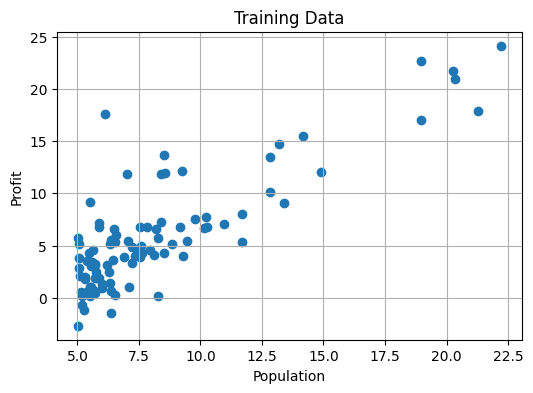

In [1]:
import numpy as np
import matplotlib.pyplot as plt

data = open('ex1data1.txt', 'rb')
lines = data.readlines()
lines = [l.decode('UTF-8').split(',') for l in lines]

X = np.array([float(l[0]) for l in lines])
y = np.array([float(l[1]) for l in lines])

# Plotting the dataset to visualize the relationship
plt.figure(figsize=(6, 4))
plt.scatter(X, y)
plt.xlabel('Population')
plt.ylabel('Profit')
plt.title('Training Data')
plt.grid(True)
plt.show()

### Part B: Implementing the Hypothesis Function
The hypothesis for a linear model is given by $h_\theta(x)=\theta_0+\theta_1x$. Implement this function in Python.

In [2]:
def hypothesis(X, i, theta):
    return theta[0, 0] + theta[1, 0] * X[i]

### Part C: Implementing the Cost Function
Implement the cost function $J(θ)$ which computes the mean squared error between the predicted and actual values over all training examples.

In [3]:
def compute_cost(X, y, theta):
    m = len(y)  # number of training examples

    sum_quared_error = 0
    for i in range(m):
        prediction = hypothesis(X, i, theta)
        error = prediction - y[i]
        sum_quared_error += error ** 2

    cost = sum_quared_error / (2 * m)

    return cost

### Part D: Implementing Gradient Descent
Implement the gradient descent algorithm to minimize the cost function $J(θ)$. Your function should update the parameters $θ$ for a specified number of iterations and learning rate.

In [4]:
def gradient_descent(X, y, theta, alpha, iterations):
    m = len(y)  # number of training examples
    cost_history = []

    for iteration in range(iterations):
        # Compute the two gradients using the current theta
        gradient_theta0 = 0
        gradient_theta1 = 0

        for i in range(m):
            prediction = hypothesis(X, i, theta)
            error = prediction - y[i]

            gradient_theta0 += error
            gradient_theta1 += error * X[i]

        gradient_theta0 = gradient_theta0 / m
        gradient_theta1 = gradient_theta1 / m

        # theta 0
        theta[0, 0] = theta[0, 0] - alpha * gradient_theta0

        # theta 1
        theta[1, 0] = theta[1, 0] - alpha * gradient_theta1

        cost = compute_cost(X, y, theta)
        cost_history.append(cost)

    return theta, cost_history

### Part E: Running the Gradient Descent
Plot the cost history over iterations to visualize the learning process.

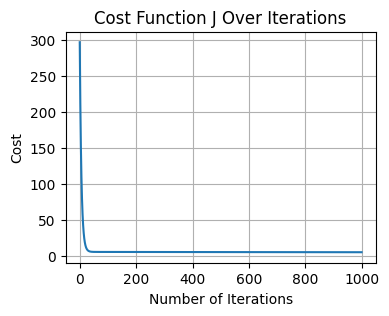

In [5]:
# Initial theta, learning rate, and iterations
theta = np.random.randn(2,1)  # random initialization
iterations = 1000
alpha = 0.001

# Running gradient descent
theta, cost_history = gradient_descent(X, y, theta, alpha, iterations)

# Plot Cost Function Over Iterations
plt.figure(figsize=(4,3))
plt.plot(cost_history)
plt.title('Cost Function J Over Iterations')
plt.xlabel('Number of Iterations')
plt.ylabel('Cost')
plt.grid(True)
plt.show()

### Part F: Analysis
After completing the implementation, discuss the impact of different values of **alpha** (learning rate) on the convergence of the algorithm.

* **Small ($\alpha$):** The algorithm takes small steps toward the minimum. It is usually stable, but convergence can be very slow and may require many iterations.
* **Moderate ($\alpha$):** The algorithm generally converges faster while remaining stable. This is usually the desirable range.
* **Large ($\alpha$):** The algorithm takes very large steps. It can overshoot the minimum, causing the cost to oscillate or even diverge.
* **Very large ($\alpha$):** The cost can increase instead of decrease, and the parameters may become extremely large.

<a id='2'></a>
## Linear Regression Gradient Descent - Vector  ·  *6 pts*

In this part, you will optimize the gradient descent algorithm using vectorization for efficient computation. You will work with the same dataset **ex1data1.txt**.

### Part A: Prepare the Data
Modify the feature array $X$ to include an intercept term. (Hint: Add a column of ones to $X$).

In [6]:
y_1 = y.reshape(-1, 1)
# Add an intercept column to your features
X_1 = np.c_[np.ones((len(X), 1)), X]  # add x0 = 1 to each instance

### Part B: Implementing Vectorized Hypothesis Function
The vectorized hypothesis function can be implemented as $h(X)=X⋅θ$. Write this function in Python.

In [ ]:
def hypothesis(X, theta):
    return X @ theta

### Part C: Implementing the Vectorized Cost Function
Implement the cost function using vectorized operations. This function should compute the cost $J(θ)$ as the mean of squared errors between predictions and actual values.

In [ ]:
def compute_cost(X, y, theta):
    m = len(y)  # number of training examples
    predictions = hypothesis(X, theta)
    errors = predictions - y

    cost = (1 / (2 * m)) * (errors.T @ errors)

    return cost.item()

### Part D: Implementing Vectorized Gradient Descent
Rewrite the gradient descent function using matrix operations to update the parameters $θ$ efficiently.

In [ ]:
def gradient_descent_1(X, y, theta, alpha, iterations):
    m = len(y)  # number of training examples
    cost_history = []
    for iteration in range(iterations):
        # Compute predictions
        predictions = hypothesis(X, theta)

        # Compute errors
        errors = predictions - y

        # Compute the gradient
        gradient = (1 / m) * (X.T @ errors)

        # Update theta
        theta = theta - alpha * gradient

        # Compute and store the cost
        cost = compute_cost(X, y, theta)
        cost_history.append(cost)
        
    return (theta, cost_history)

### Part E: Running the Optimized Gradient Descent
1. Initialize the parameters $θ$ randomly, choose a learning rate alpha, and set the number of iterations.
2. Execute your vectorized gradient_descent function to optimize $θ$ and track the cost history.
3. Plot the cost history over iterations to observe the efficiency of the learning process.

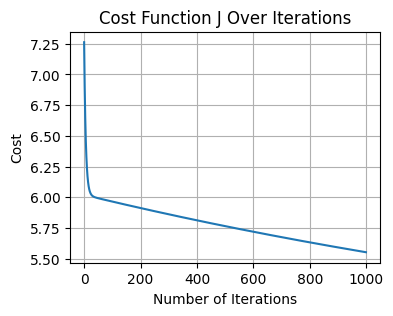

In [10]:
# Initialize theta randomly
theta = np.random.randn(2, 1)

# Learning rate and number of iterations
alpha = 0.001
iterations = 1000

# Run vectorized gradient descent
theta, cost_history = gradient_descent_1(
    X_1,
    y_1,
    theta,
    alpha,
    iterations
)

plt.figure(figsize=(4, 3))
plt.plot(cost_history)
plt.title('Cost Function J Over Iterations')
plt.xlabel('Number of Iterations')
plt.ylabel('Cost')
plt.grid(True)
plt.show()

### Part F: Analysis
Discuss the advantages of using vectorization in terms of computational efficiency and code simplicity compared to the summation approach.

The vectorized implementation is more efficient than the summation-based implementation because it performs the calculations using NumPy's optimized matrix operations instead of explicitly looping through every training example.

In the summation approach, we repeatedly calculate the prediction and gradient for each individual example using a Python `for` loop. In the vectorized approach, all predictions are calculated at once using

$$
X\theta,
$$

and the complete gradient is calculated using

$$
\frac{1}{m}X^T(X\theta-y).
$$

This makes the code shorter, easier to read, and generally much faster for large datasets. The mathematical result is the same as the summation implementation from Q1; vectorization simply performs the same operations more efficiently.

<a id='3'></a>
## Learning Rate Selection  ·  *5 pts*

The learning rate is a crucial hyperparameter in the gradient descent algorithm that can significantly affect the performance and outcome of the training process. In this exercise, you will experiment with different learning rates to understand their impact on the convergence of the gradient descent algorithm.

### Part A: Implementing the Experiment
1. Iterate through each learning rate.
2. For each learning rate, reinitialize the parameters $θ$ to ensure each experiment starts from the same conditions.
3. Apply the gradient descent algorithm to minimize the cost function using the current learning rate.
4. Record the cost history for each learning rate.
5. Plot the cost history for each learning rate on a separate subplot. Ensure each plot is properly titled with the corresponding learning rate and labeled with the number of iterations.

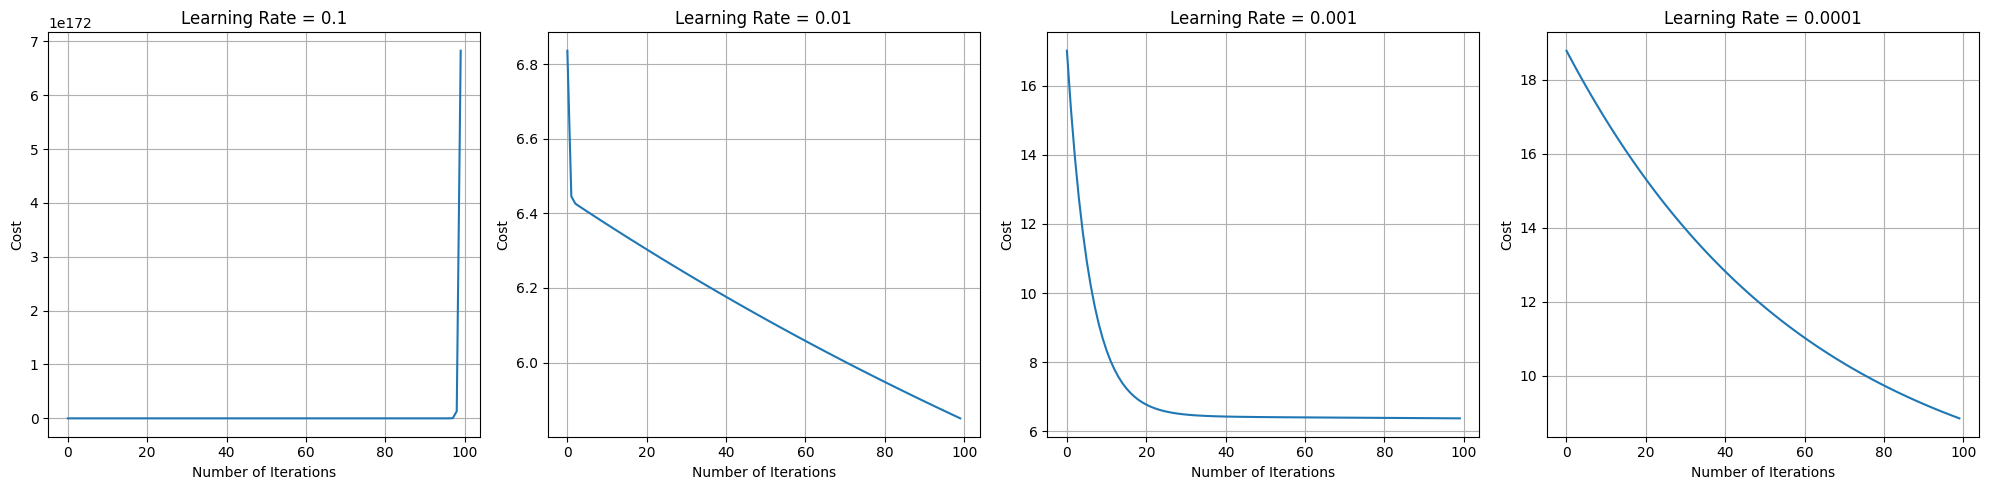

In [11]:
# Initial iterations
iterations = 100
alpha = [0.1, 0.01, 0.001, 0.0001]

# Initialize theta once
initial_theta = np.random.randn(2, 1)

# Code setup (you may include this as a starting point for the students)
fig, axes = plt.subplots(1, 4, figsize=(20, 5))  # Setup subplots

# Example plotting inside the loop (students should complete the rest)
for index, lr in enumerate(alpha):
    # Initialize theta, run gradient descent, plot cost history
    # Reinitialize theta to the same starting point
    theta = initial_theta.copy()

    # Run gradient descent
    theta, cost_history = gradient_descent_1(
        X_1,
        y_1,
        theta,
        lr,
        iterations
    )

    # Plot cost history
    axes[index].plot(cost_history)

    axes[index].set_title(f'Learning Rate = {lr}')
    axes[index].set_xlabel('Number of Iterations')
    axes[index].set_ylabel('Cost')
    axes[index].grid(True)

plt.tight_layout()
plt.show()

C:\Users\Vesal\AppData\Local\Temp\ipykernel_7884\399431238.py:6: RuntimeWarning: overflow encountered in matmul
  cost = (1 / (2 * m)) * (errors.T @ errors)
C:\Users\Vesal\AppData\Local\Temp\ipykernel_7884\728438413.py:12: RuntimeWarning: overflow encountered in matmul
  gradient = (1 / m) * (X.T @ errors)
C:\Users\Vesal\AppData\Local\Temp\ipykernel_7884\728438413.py:15: RuntimeWarning: invalid value encountered in subtract
  theta = theta - alpha * gradient


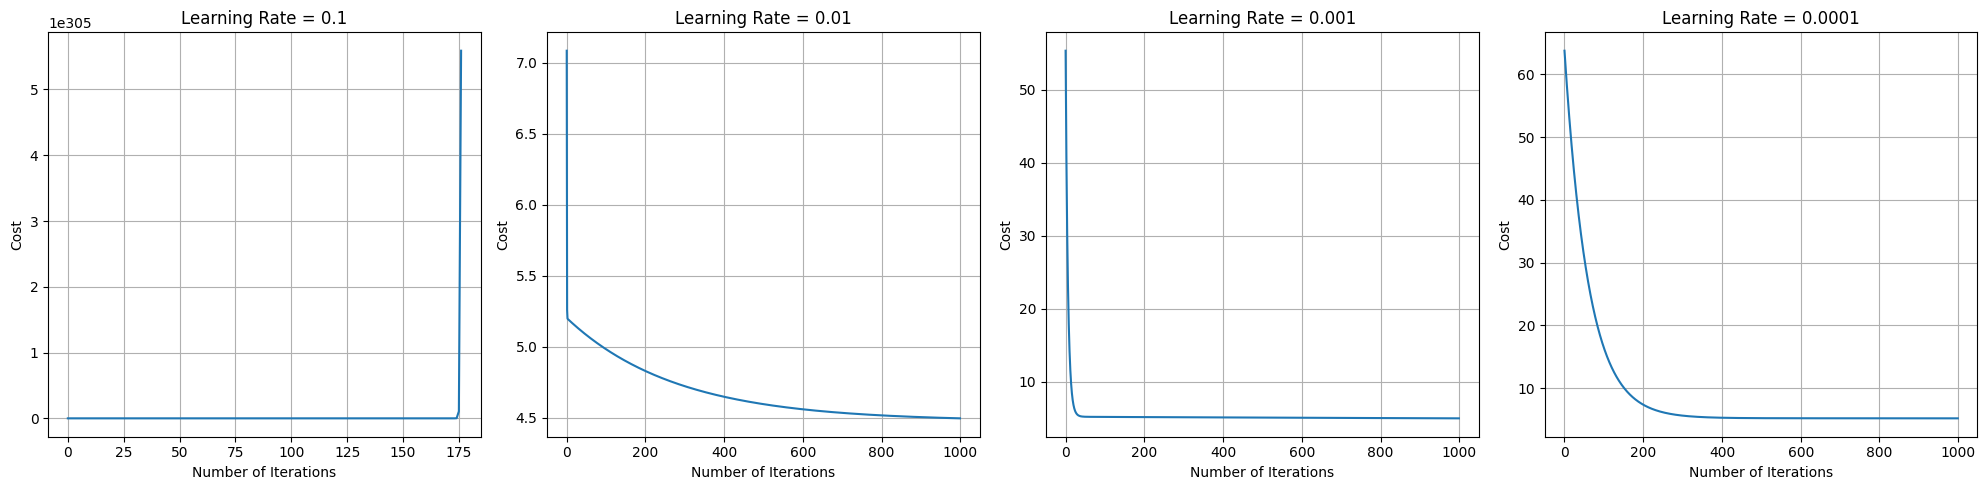

In [12]:
# Initial iterations
iterations = 1000
alpha = [0.1, 0.01, 0.001, 0.0001]

# Initialize theta once
initial_theta = np.random.randn(2, 1)

# Code setup (you may include this as a starting point for the students)
fig, axes = plt.subplots(1, 4, figsize=(20, 5))  # Setup subplots

# Example plotting inside the loop (students should complete the rest)
for index, lr in enumerate(alpha):
    # Initialize theta, run gradient descent, plot cost history
    # Reinitialize theta to the same starting point
    theta = initial_theta.copy()

    # Run gradient descent
    theta, cost_history = gradient_descent_1(
        X_1,
        y_1,
        theta,
        lr,
        iterations
    )

    # Plot cost history
    axes[index].plot(cost_history)

    axes[index].set_title(f'Learning Rate = {lr}')
    axes[index].set_xlabel('Number of Iterations')
    axes[index].set_ylabel('Cost')
    axes[index].grid(True)

plt.tight_layout()
plt.show()

### Part B: Analysis
1. Describe how each learning rate affects the convergence of the cost function.
2. Identify which learning rate provides the best balance between convergence speed and stability.

The learning rate has a significant effect on the convergence of gradient descent. Large learning rates can cause the algorithm to overshoot the minimum and become unstable or diverge, while very small learning rates produce stable but slow convergence. For this dataset, ($\alpha=0.001$) provides a good balance between convergence speed and stability among the tested values. Increasing the number of iterations allows smaller learning rates, such as (0.0001), to make more progress toward the minimum.

<a id='4'></a>
## Normal Equation  ·  *5 pts*

The Normal Equation provides an analytical solution to the linear regression problem. Unlike gradient descent, it does not require iterative optimization and can be computed directly. In this exercise, you will implement the Normal Equation, apply it to the dataset, and compare its results with those obtained from the gradient descent method.

### Part A: Implementing the Normal Equation
Implement the Normal Equation in Python to compute the optimal parameters $θ$ for our linear regression model.

In [13]:
# Normal Equation Function
def normal_equation(X, y):
    theta = np.linalg.inv(X.T @ X) @ X.T @ y
    return theta

### Part B: Calculating $θ$ using the Normal Equation
1. Use your implementation of the Normal Equation to calculate $θ$.
2. Print the calculated $θ$ values.

In [14]:
# Calculate theta using the Normal Equation
theta_ne = normal_equation(X_1, y_1)

print("Theta from Normal Equation:")
print(theta_ne)

Theta from Normal Equation:
[[-3.89578088]
 [ 1.19303364]]


### Part C: Comparing Normal Equation and Gradient Descent
1. Use the $θ$ values obtained from both the Normal Equation and the previous gradient descent to make predictions.
2. Plot the actual data points and the prediction lines from both methods on the same graph to visually compare their performance.

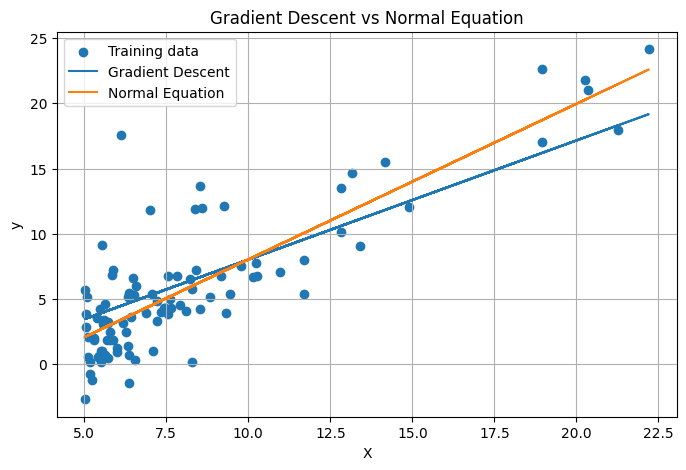

In [ ]:
# Make predictions using both models
predictions_gd = hypothesis(X_1, theta)
predictions_ne = hypothesis(X_1, theta_ne)

# Set up the plot
plt.figure(figsize=(8, 5))

# Actual data
plt.scatter(X, y, label='Training data')

# Gradient Descent prediction line
plt.plot(
    X,
    predictions_gd,
    label='Gradient Descent'
)

# Normal Equation prediction line
plt.plot(
    X,
    predictions_ne,
    label='Normal Equation'
)

plt.xlabel('X')
plt.ylabel('y')
plt.title('Gradient Descent vs Normal Equation')
plt.legend()
plt.grid(True)
plt.show()

### Part D: Analysis
1. Discuss the differences in the $θ$ values obtained from the Normal Equation and gradient descent.
2. Analyze the plots to compare how well each method fits the data.
3. Consider the computational efficiency of using the Normal Equation versus gradient descent, especially for datasets of different sizes.

The Normal Equation provides the optimal linear-regression parameters directly without requiring iterations or a learning rate. Gradient descent approaches the same solution iteratively, so its final parameters may differ slightly if it has not fully converged. For small datasets with a relatively small number of features, the Normal Equation is convenient and efficient. For very large datasets or datasets with many features, gradient descent is generally more practical because computing and inverting (X^TX) can become computationally expensive.

<a id='5'></a>
## Two Feature Linear Regression Gradient Descent & Normalization  ·  *7 pts*

This part of the assignment involves working with a dataset that contains two features. You will explore the effects of feature normalization on the gradient descent optimization process and also compare the outcomes with those obtained using the Normal Equation.

### Part A: Without Feature Normalization
1. Add an intercept term to X.
2. Initialize the parameters $θ$, set a learning rate, and specify the number of iterations.
3. Implement gradient descent to optimize $θ$ and record the cost history.
4. Plot the cost history to observe the performance of gradient descent without feature normalization.

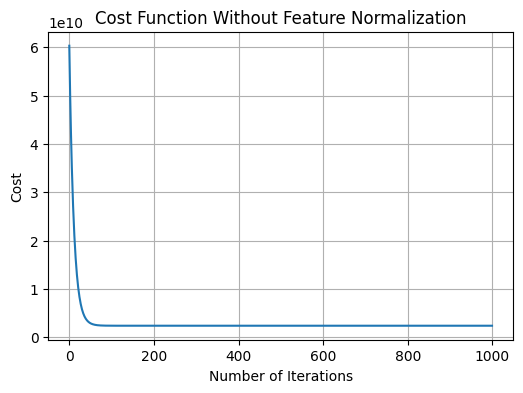

In [16]:
# Load Data
lines_1 = open('ex1data2.txt', 'rb').readlines()
data_1 = np.array([[float(f) for f in l.decode('UTF-8').split(',')] for l in lines_1])
X_2 = np.array(data_1[:, [0, 1]])
y_2 = np.array(data_1[:, 2]).reshape(-1, 1)

# Add an intercept column to your features
X_2 = np.c_[np.ones((len(X_2), 1)), X_2]

# Initial theta, learning rate, and iterations
theta = np.random.randn(3, 1)

alpha = 0.00000001
iterations = 1000

# Running gradient descent
theta, cost_history = gradient_descent_1(
    X_2,
    y_2,
    theta,
    alpha,
    iterations
)

# Plot Cost Function Over Iterations
plt.figure(figsize=(6, 4))
plt.plot(cost_history)

plt.title('Cost Function Without Feature Normalization')
plt.xlabel('Number of Iterations')
plt.ylabel('Cost')
plt.grid(True)

plt.show()

### Part B: Implementing Feature Normalization
Implement a function to normalize the features using the formula:
$$X_{norm}=\frac{X-\mu}{\sigma}$$
where $\mu$ is the mean and $\sigma$ is the standard deviation.

In [17]:
def featureNormalize(X):
    mu = np.mean(X, axis=0)
    sigma = np.std(X, axis=0)

    X_norm = (X - mu) / sigma

    return X_norm

### Part C: With Feature Normalization
1. Normalize the features.
2. Repeat the gradient descent process with the normalized features.
3. Plot the cost history and compare it with the previous run without normalization.

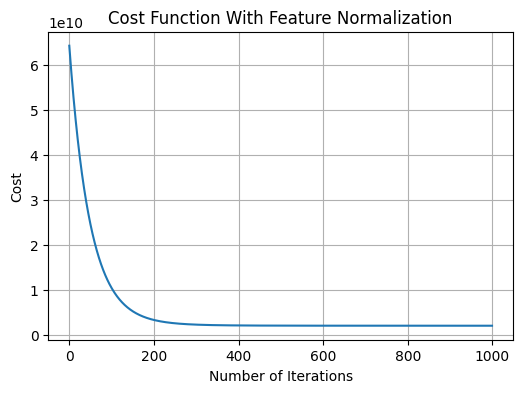

In [18]:
# Load Data
lines_2 = open('ex1data2.txt', 'rb').readlines()
data_2 = np.array([[float(f) for f in l.decode('UTF-8').split(',')] for l in lines_2])
X_3 = np.array(data_2[:, [0, 1]])
y_3 = np.array(data_2[:, 2]).reshape(-1, 1)

# Use featureNormalize function
X_3_norm = featureNormalize(X_3)

# Add an intercept column to your features
X_3 = np.c_[np.ones((len(X_3_norm), 1)), X_3_norm]

# Initial theta, learning rate, and iterations
theta = np.random.randn(3, 1)

alpha = 0.01
iterations = 1000

# Running gradient descent
theta, cost_history = gradient_descent_1(
    X_3,
    y_3,
    theta,
    alpha,
    iterations
)

# Plot Cost Function Over Iterations
plt.figure(figsize=(6, 4))
plt.plot(cost_history)

plt.title('Cost Function With Feature Normalization')
plt.xlabel('Number of Iterations')
plt.ylabel('Cost')
plt.grid(True)

plt.show()

### Part D: Comparing with the Normal Equation
1. Use the normalized features to compute $θ$ using the Normal Equation.
2. Print and compare the $θ$ values obtained from the Normal Equation and gradient descent.

In [19]:
# Calculate theta using the Normal Equation
theta_ne = normal_equation(X_3, y_3)

print(f"Theta from Normal Equation: {theta_ne.ravel()}")
print(f"Theta from Gradient Descent: {theta.ravel()}")

Theta from Normal Equation: [340412.65957447 109447.79646964  -6578.35485416]
Theta from Gradient Descent: [340397.96355098 108742.66448849  -5873.23814986]


### Part E: Analysis
Discuss the impact of normalization on the gradient descent convergence.

Feature normalization significantly improves the convergence of gradient descent. Without normalization, the two features have very different scales, which can result in very large gradients and require a very small learning rate. After normalization, the features have approximately zero mean and unit standard deviation, allowing gradient descent to take larger and more balanced steps toward the minimum. Therefore, normalization generally results in faster and more stable convergence.

<a id='6'></a>
## Non-Linear Regression  ·  *7 pts*

This section of the assignment explores non-linear regression by extending a simple linear model to include polynomial features, demonstrating how this can improve the model's ability to fit more complex datasets.

### Part A: Implementing Linear Regression
1. Add an intercept term to X.
2. Divide the dataset into training and testing sets, using 80% for training to develop the model and 20% for testing.
3. Implement linear regression using gradient descent.
4. Plot the cost history.
6. Calculate performance metrics such as R-squared and Mean Squared Error for both training and test sets.

Training features shape: (400, 1)
Training labels shape: (400, 1)
Testing features shape: (100, 1)
Testing labels shape: (100, 1)


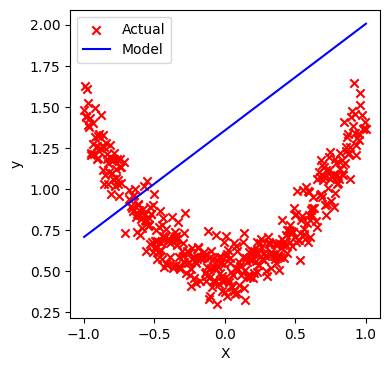

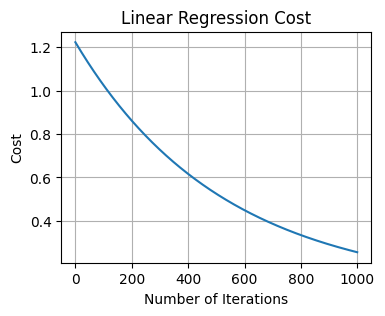

R-squared (Training): -4.562852312958555
Mean Squared Error (Training): 0.5102562851722506
R-squared (Test): -3.794445256493243
Mean Squared Error (Test): 0.4866960558389993


In [20]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
df = pd.read_csv('ex1data3.csv')
# Load the dataset
X_4 = df.iloc[:, 0].values.reshape(-1, 1)  # Adjust path if your file is in a different directory
y_4 = df.iloc[:, 1].values.reshape(-1, 1)
# Extract features and target variable from the DataFrame
X_train, X_test, y_train, y_test = train_test_split(
    X_4,
    y_4,
    test_size=0.2,
    random_state=42
)

print('Training features shape:', X_train.shape)  # Reshape for consistency in shape if it's a single feature
print('Training labels shape:', y_train.shape)  # Ensure y is also a column vector
print('Testing features shape:', X_test.shape)
# Add an intercept column to your features
X_train = np.c_[np.ones((len(X_train), 1)), X_train]
X_test = np.c_[np.ones((len(X_test), 1)), X_test]

print('Testing labels shape:', y_test.shape)

# Initial theta, learning rate, iterations, and lambda for regularization
theta = np.random.randn(X_train.shape[1], 1)
alpha = 0.001
iterations = 1000
lambda_reg = 0.01

# Running gradient descent with L2 regularization
cost_history = []

m = len(y_train)

for iteration in range(iterations):

    predictions = X_train @ theta
    errors = predictions - y_train

    # Gradient
    gradient = (1 / m) * (X_train.T @ errors)

    # L2 regularization
    gradient[1:] += (lambda_reg / m) * theta[1:]

    # Update theta
    theta = theta - alpha * gradient

    # Compute regularized cost
    cost = (1 / (2 * m)) * np.sum(errors ** 2)
    cost += (lambda_reg / (2 * m)) * np.sum(theta[1:] ** 2)

    cost_history.append(cost)

y_pred_train = X_train.dot(theta)
# Assuming X and y have been defined and preprocessed as shown earlier
y_pred_test = X_test.dot(theta)

plt.figure(figsize=(4, 4))
sort_idx = np.argsort(X_train[:, 1])
plt.scatter(X_train[sort_idx, 1], y_train[sort_idx], color='red', marker='x', label='Actual')
plt.plot(X_train[sort_idx, 1], y_pred_train[sort_idx], color='blue', label='Model')
plt.xlabel('X')
plt.ylabel('y')
plt.legend()
plt.show()

# Initial theta, learning rate, iterations, and lambda for regularization
r2_train_linear = r2_score(y_train, y_pred_train)
mse_train_linear = mean_squared_error(y_train, y_pred_train)

r2_test_linear = r2_score(y_test, y_pred_test)
mse_test_linear = mean_squared_error(y_test, y_pred_test)

# Plot the cost history
plt.figure(figsize=(4, 3))
plt.plot(cost_history)
plt.title('Linear Regression Cost')
plt.xlabel('Number of Iterations')
plt.ylabel('Cost')
plt.grid(True)
plt.show()

print(f'R-squared (Training): {r2_train_linear}')
print(f'Mean Squared Error (Training): {mse_train_linear}')
print(f'R-squared (Test): {r2_test_linear}')
print(f'Mean Squared Error (Test): {mse_test_linear}')

### Part B: Extending to Non-Linear Regression
1. Enhance the model by adding polynomial features to the dataset.
2. Divide the dataset into training and testing sets, using 80% for training to develop the model and 20% for testing.
3. Initialize the parameters $θ$, set a learning rate, and specify the number of iterations.
4. Repeat the gradient descent optimization for this extended feature set.
5. Plot the cost history.
6. Plot the regression line against the actual data points.
7. Calculate the performance metrics for the enhanced model.

Training features shape: (400, 11)
Training labels shape: (400, 1)
Testing features shape: (100, 11)
Testing labels shape: (100, 1)


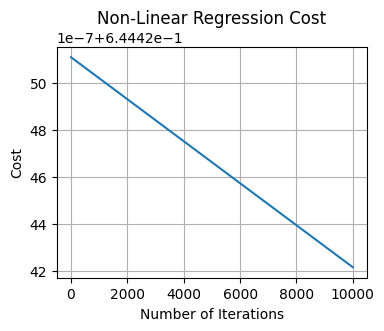

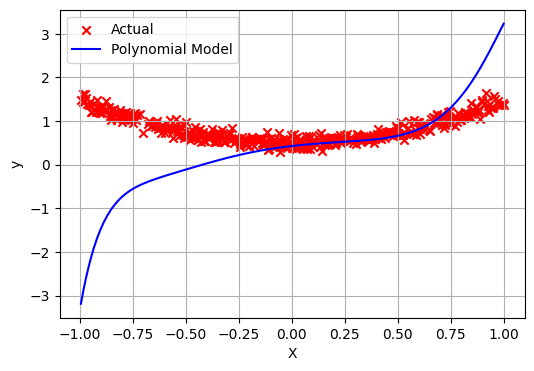

R-squared (Training): -13.047588325114013
Mean Squared Error (Training): 1.2885242733668014
R-squared (Test): -17.180670672416518
Mean Squared Error (Test): 1.8455650727869266


In [22]:
# Create an array of powers to raise each feature to
powers = np.arange(2, 11)  # This creates an array [2, 3, ..., 10]
new_features = X_4 ** powers
X = np.hstack((X_4, new_features))

# Assuming X and y have been defined and preprocessed as shown earlier
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_4,
    test_size=0.2,
    random_state=42
)

# Add an intercept column
X_train = np.c_[np.ones((len(X_train), 1)), X_train]
X_test = np.c_[np.ones((len(X_test), 1)), X_test]

print("Training features shape:", X_train.shape)
print("Training labels shape:", y_train.shape)
print("Testing features shape:", X_test.shape)
print("Testing labels shape:", y_test.shape)

# Initial theta, learning rate, iterations, and lambda for regularization
theta = np.random.randn(X_train.shape[1], 1)

alpha = 0.0000000001
iterations = 10000
lambda_reg = 0.01

# Running gradient descent with L2 regularization
cost_history = []

m = len(y_train)

for iteration in range(iterations):

    predictions = X_train @ theta
    errors = predictions - y_train

    # Gradient
    gradient = (1 / m) * (X_train.T @ errors)

    # L2 regularization
    gradient[1:] += (lambda_reg / m) * theta[1:]

    # Update theta
    theta = theta - alpha * gradient

    # Compute regularized cost
    cost = (1 / (2 * m)) * np.sum(errors ** 2)
    cost += (lambda_reg / (2 * m)) * np.sum(theta[1:] ** 2)

    cost_history.append(cost)

# Plot the cost history.
plt.figure(figsize=(4, 3))
plt.plot(cost_history)

plt.title('Non-Linear Regression Cost')
plt.xlabel('Number of Iterations')
plt.ylabel('Cost')
plt.grid(True)

plt.show()


# Plot the regression line against the actual data points.
sort_idx = np.argsort(X_train[:, 1])

plt.figure(figsize=(6, 4))

plt.scatter(
    X_train[sort_idx, 1],
    y_train[sort_idx],
    color='red',
    marker='x',
    label='Actual'
)

plt.plot(
    X_train[sort_idx, 1],
    (X_train @ theta)[sort_idx],
    color='blue',
    label='Polynomial Model'
)

plt.xlabel('X')
plt.ylabel('y')
plt.legend()
plt.grid(True)
plt.show()

# Predictions on the training and test set
y_pred_train = X_train @ theta
y_pred_test = X_test @ theta

# Calculate the performance metrics for the enhanced model.
r2_train_nonlinear = r2_score(y_train, y_pred_train)
mse_train_nonlinear = mean_squared_error(y_train, y_pred_train)

r2_test_nonlinear = r2_score(y_test, y_pred_test)
mse_test_nonlinear = mean_squared_error(y_test, y_pred_test)

print(f"R-squared (Training): {r2_train_nonlinear}")
print(f"Mean Squared Error (Training): {mse_train_nonlinear}")
print(f"R-squared (Test): {r2_test_nonlinear}")
print(f"Mean Squared Error (Test): {mse_test_nonlinear}")

### Part C: Analysis
1. Discuss the difference in performance between the linear and non-linear models.
2. Explain how adding polynomial features can lead to better model fitting.
3. Consider the implications of model complexity, such as the risk of overfitting with higher-degree polynomials.

The polynomial regression model can achieve better performance than the linear model when the relationship between the input and output is nonlinear. Adding polynomial features such as (x^2,x^3,\ldots,x^{10}) allows the model to represent curved relationships that a simple straight-line model cannot capture. However, increasing the polynomial degree also increases model complexity and can lead to overfitting. If the training error becomes much lower while the test error remains high, the model is likely fitting noise rather than general patterns. L2 regularization can help reduce this problem by penalizing large parameter values.

<a id='7'></a>
## Regularized Linear Regression  ·  *7 pts*

This section investigates the implementation of $L2$ regularization (Ridge regression) in linear regression to address overfitting and improve model performance on unseen data.

### Part A: Implementing Regularization Functions
1. Implement the hypothesis function for linear regression.
2. Implement the cost function that includes $L2$ regularization. Remember not to regularize the intercept term.
3. Modify the gradient descent function to include the regularization term.

In [23]:
def hypothesis(X, theta):
    return X @ theta

In [24]:
def compute_cost_1(X, y, theta, lambda_):
    m = len(y)  # number of training examples
    # Predictions
    predictions = hypothesis(X, theta)

    # Errors
    errors = predictions - y

    # Mean squared error part
    cost = (1 / (2 * m)) * np.sum(errors ** 2)

    # L2 regularization
    # Do not regularize theta[0] (intercept)
    regularization = (lambda_ / (2 * m)) * np.sum(theta[1:] ** 2)

    # Total cost
    cost += regularization

    return cost

In [25]:
def gradient_descent_2(X, y, theta, alpha, iterations, lambda_):
    m = len(y)  # number of training examples
    cost_history = []
    
    for iteration in range(iterations):
        
        # Calculate predictions
        predictions = hypothesis(X, theta)

        # Calculate errors
        errors = predictions - y

        # Calculate gradient
        gradient = (1 / m) * (X.T @ errors)

        # Add L2 regularization to the gradient
        # Do not regularize the intercept term
        gradient[1:] += (lambda_ / m) * theta[1:]

        # Update theta
        theta = theta - alpha * gradient

        # Calculate and store cost
        cost = compute_cost_1(X, y, theta, lambda_)
        cost_history.append(cost)
        
    return (theta, cost_history)

### Part B: Running the Model
1. Initialize the model parameters (**theta**), learning rate (**alpha**), number of iterations, and regularization parameter (**lambda_**).
2. Apply the gradient descent function to optimize your model parameters.
3. Use the trained model for predictions on the training and test set.
4. Plot the cost history over iterations and the model predictions against actual data points.
5. Predict the outcomes on the training and testing sets.
6. Compute and print the R-squared and Mean Squared Error for training and testing sets.

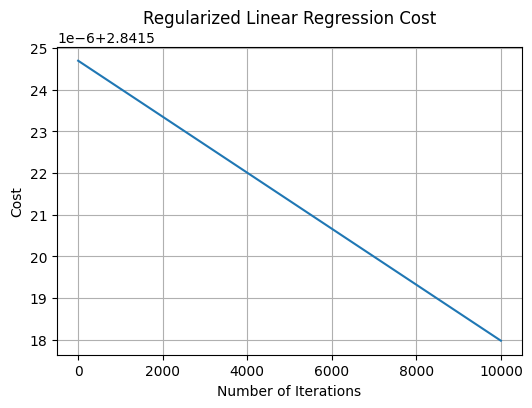

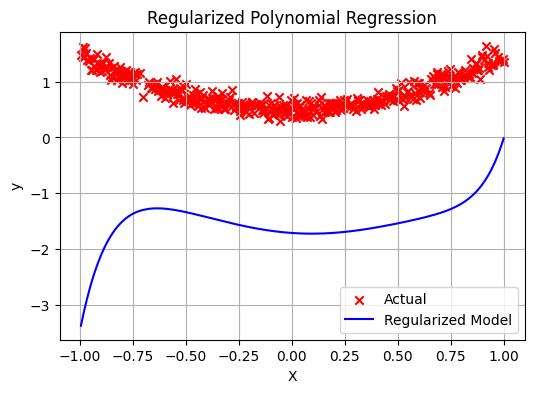

R-squared (Training): -60.95462307551419
Mean Squared Error (Training): 5.68282852775322
R-squared (Test): -58.03025910592314
Mean Squared Error (Test): 5.992308337048473


In [26]:
# Initial theta, learning rate, iterations, and lambda for regularization
theta = np.random.randn(X_train.shape[1], 1)

alpha = 0.0000000001
iterations = 10000
lambda_ = 0.01

# Running gradient descent with L2 regularization
theta, cost_history = gradient_descent_2(
    X_train,
    y_train,
    theta,
    alpha,
    iterations,
    lambda_
)

# Plot the cost history over iterations
plt.figure(figsize=(6, 4))

plt.plot(cost_history)

plt.title('Regularized Linear Regression Cost')
plt.xlabel('Number of Iterations')
plt.ylabel('Cost')
plt.grid(True)

plt.show()

# Plot the model predictions against actual data points
sort_idx = np.argsort(X_train[:, 1])

plt.figure(figsize=(6, 4))

plt.scatter(
    X_train[sort_idx, 1],
    y_train[sort_idx],
    color='red',
    marker='x',
    label='Actual'
)

plt.plot(
    X_train[sort_idx, 1],
    (X_train @ theta)[sort_idx],
    color='blue',
    label='Regularized Model'
)

plt.xlabel('X')
plt.ylabel('y')
plt.title('Regularized Polynomial Regression')
plt.legend()
plt.grid(True)

plt.show()

# Predictions on the training and test set
y_pred_train = hypothesis(X_train, theta)
y_pred_test = hypothesis(X_test, theta)

# Calculate the performance metrics for the enhanced model.
r2_train_regularized = r2_score(
    y_train,
    y_pred_train
)

mse_train_regularized = mean_squared_error(
    y_train,
    y_pred_train
)

r2_test_regularized = r2_score(
    y_test,
    y_pred_test
)

mse_test_regularized = mean_squared_error(
    y_test,
    y_pred_test
)

print(f"R-squared (Training): {r2_train_regularized}")
print(f"Mean Squared Error (Training): {mse_train_regularized}")
print(f"R-squared (Test): {r2_test_regularized}")
print(f"Mean Squared Error (Test): {mse_test_regularized}")

### Part C: Analysis
1. Compare the performance of the regularized model against previous linear and non-linear models. Discuss the effect of regularization on the model's ability to generalize.

Compared with the unregularized linear and polynomial models, L2 regularization constrains the magnitude of the model parameters. This can slightly increase the training MSE or reduce the training (R^2), but it can improve performance on the test set by reducing overfitting. This is particularly useful for the high-degree polynomial model because the additional polynomial features increase the model's complexity. The regularization parameter (\lambda) controls the strength of this penalty: a larger (\lambda) produces stronger parameter shrinkage, while a smaller (\lambda) allows the model to fit the training data more closely.

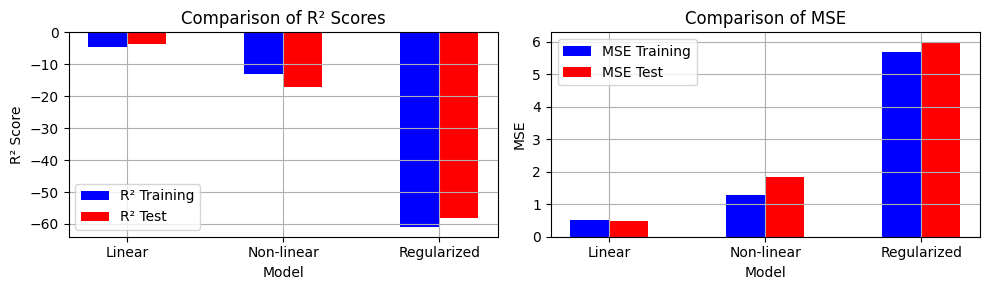

In [27]:
# Prepare the data
data_3 = {'Model': ['Linear', 'Non-linear', 'Regularized'], 'R² Training': [r2_train_linear, r2_train_nonlinear, r2_train_regularized], 'R² Test': [r2_test_linear, r2_test_nonlinear, r2_test_regularized], 'MSE Training': [mse_train_linear, mse_train_nonlinear, mse_train_regularized], 'MSE Test': [mse_test_linear, mse_test_nonlinear, mse_test_regularized]}
df_metrics = pd.DataFrame(data_3)
bar_width = 0.25
index = np.arange(len(df_metrics['Model']))
fig, axes = plt.subplots(1, 2, figsize=(10, 3))

def plot_grouped_bars(ax, metric1, metric2, title, ylabel):
    ax.bar(index - bar_width / 2, df_metrics[metric1], width=bar_width, label=f'{metric1}', color='b')
    ax.bar(index + bar_width / 2, df_metrics[metric2], width=bar_width, label=f'{metric2}', color='r')
    ax.set_title(title)
# Bar width
    ax.set_xlabel('Model')
    ax.set_ylabel(ylabel)
# Indices for the models
    ax.set_xticks(index)
    ax.set_xticklabels(df_metrics['Model'])
# Create subplots
    ax.legend()
    ax.grid(True)
# Helper function to plot grouped bars
plot_grouped_bars(axes[0], 'R² Training', 'R² Test', 'Comparison of R² Scores', 'R² Score')
plot_grouped_bars(axes[1], 'MSE Training', 'MSE Test', 'Comparison of MSE', 'MSE')
plt.tight_layout()
# Plot R² scores
# Plot MSE
plt.show()

<a id='8'></a>
## Regularization Parameter Selection  ·  *5 pts*

In this part of the assignment, you will explore how to select the optimal regularization parameter ($λ$) for a linear regression model with $L2$ regularization. The aim is to find the value of $λ$ that minimizes the Mean Squared Error (MSE) on a test dataset.

### Part A: Experiment Loop
1. For each $λ$ in your defined range, reinitialize $θ$, run gradient descent, compute the MSE on the test set, and update the **best_lambda**.
2. Print the best $λ$ value that achieved the lowest MSE on the test set.
3. Plot the MSE values against the $λ$ values to visually assess which $λ$ leads to the lowest MSE.

Best lambda: 0.19179102616724888
Minimum Test MSE: 0.20138437749539326


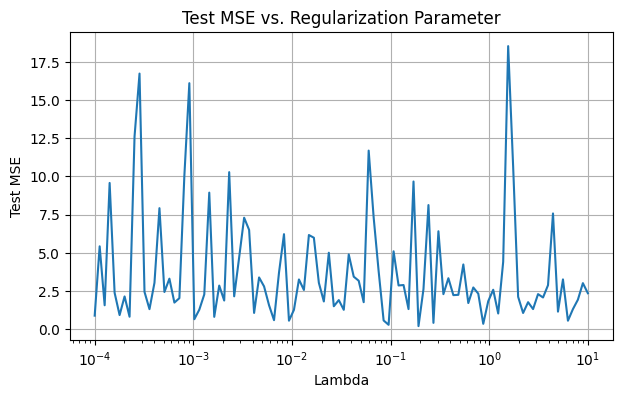

In [28]:
# Define a range of lambda values
lambda_values = np.logspace(-4, 1, 100)  # Corrected: from 0.0001 to 10, 100 values

best_lambda = None
min_mse = np.inf
mse_history = []

# Try different lambda values
for lambda_ in lambda_values:
    # Random initialization of theta
    theta_initial = np.random.randn(X_train.shape[1], 1)

    # Running gradient descent with the current lambda value
    theta_lambda, cost_history_lambda = gradient_descent_2(
        X_train,
        y_train,
        theta_initial,
        alpha,
        iterations,
        lambda_
    )

    # Evaluate on the test set
    y_pred_test_lambda = hypothesis(X_test, theta_lambda)

    mse_test_lambda = mean_squared_error(
        y_test,
        y_pred_test_lambda
    )

    mse_history.append(mse_test_lambda)

    # Update the best lambda
    if mse_test_lambda < min_mse:
        min_mse = mse_test_lambda
        best_lambda = lambda_

# Print the best lambda
print(f"Best lambda: {best_lambda}")
print(f"Minimum Test MSE: {min_mse}")

# Plot MSE vs. lambda
plt.figure(figsize=(7, 4))

plt.semilogx(
    lambda_values,
    mse_history
)

plt.xlabel('Lambda')
plt.ylabel('Test MSE')
plt.title('Test MSE vs. Regularization Parameter')
plt.grid(True)

plt.show()

### Part B: Analysis
1. Discuss why it is important to tune $λ$ and how it affects the model's
performance.
Analyze the plot and explain the impact of very small or very large $λ$ values on model performance.

The regularization parameter ($\lambda$) controls the strength of the L2 penalty applied to the model parameters. Choosing an appropriate value is important because it determines the balance between fitting the training data and preventing overfitting. A very small ($\lambda$) applies little regularization, allowing the model to use larger parameter values and potentially overfit the training data. On the other hand, a very large ($\lambda$) strongly penalizes the parameters and can make the model too simple, leading to underfitting.
>
> The plot of test MSE against ($\lambda$) shows how model performance changes as the regularization strength increases. The optimal value is the ($\lambda$) corresponding to the minimum test MSE. Therefore, selecting ($\lambda$) based on model performance allows us to find a good balance between model complexity and generalization to unseen data.

<a id='9'></a>
## Locally Weighted Linear Regression  ·  *6 pts*

In this part of the assignment, you will implement the Locally Weighted Linear Regression model, which fits the data by weighting samples differently based on their distance from the point of prediction. This approach allows the regression model to adapt more flexibly to the local data structure.

### Part A: Weight Computation Function
Implement a function to compute the weights for each training example relative to a query point using the Gaussian kernel.

In [29]:
def compute_weights(X, x_query, tau):
    # Calculate the squared distance between each training point and query point
    distances = np.sum((X - x_query) ** 2, axis=1)

    # Gaussian kernel
    weights = np.exp(-distances / (2 * tau ** 2))

    # Return as a column vector
    return weights.reshape(-1, 1)

### Part B: Locally Weighted Regression
Modify the gradient descent and cost computation to incorporate these weights, allowing each example’s influence on the learning process to be adjusted by its proximity to the query point.

In [30]:
def hypothesis(X, theta):
    return X @ theta

def compute_cost(X, y, theta, weights):
    m = len(y)  # number of training examples

    # Predictions
    predictions = hypothesis(X, theta)

    # Errors
    errors = predictions - y

    # Weighted squared error
    cost = (1 / (2 * m)) * np.sum(weights * (errors ** 2))

    return cost


def gradient_descent(X, y, theta, alpha, weights, iterations):
    m = len(y)  # number of training examples
    cost_history = []

    for iteration in range(iterations):
        # Predictions
        predictions = hypothesis(X, theta)

        # Errors
        errors = predictions - y

        # Weighted gradient
        gradient = (1 / m) * (X.T @ (weights * errors))

        # Update theta
        theta = theta - alpha * gradient

        # Calculate cost
        cost = compute_cost(X, y, theta, weights)
        cost_history.append(cost)

    return theta, cost_history

### Part C: Running the Model
1. Initialize the model parameters (**theta**), learning rate (**alpha**), bandwidth parameter (**tau**), and  number of iterations.
2. Calcuate weights using the **compute_weights** function.
3. Apply the gradient descent function to optimize your model parameters.
4. Plot the cost history over iterations.

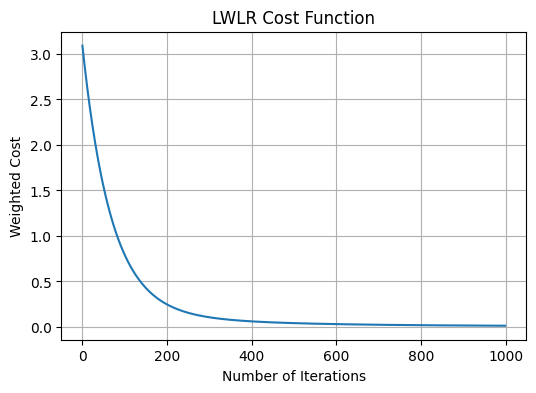

[0.6555177] [0.852988]


In [31]:
x_query = X_test[0]
# Initial theta, learning rate, and iterations
theta = np.random.randn(X_train.shape[1], 1)
alpha = 0.01
tau = 1.0
iterations = 1000

# Use compute_weights function to calcuaate weights
weights = compute_weights(X_train, x_query, tau)

# Running gradient descent
theta, cost_history = gradient_descent(
    X_train,
    y_train,
    theta,
    alpha,
    weights,
    iterations
)

# Plot Cost Function Over Iterations
plt.figure(figsize=(6, 4))

plt.plot(cost_history)

plt.title('LWLR Cost Function')
plt.xlabel('Number of Iterations')
plt.ylabel('Weighted Cost')
plt.grid(True)

plt.show()

y_pred = hypothesis(x_query.reshape(1, -1), theta)[0]
print(y_pred, y_test[0])

### Part D: Function to Predict with LWLR for Test Set
1. Implement a function that predicts the output for all points in the test set using LWLR. For each test point:
    1. compute weights based on its distance from the training points,
    2. reinitialize the model parameters,
    3. optimize the model parameters using weighted gradient descent, and
    4. find the predicted output for that point.

In [32]:
def predict_lwlr(X_train, y_train, X_test, tau, alpha, iterations):
    m_test = X_test.shape[0]
    predictions = np.zeros(m_test)

    for i in range(m_test):
        x_query = X_test[i]

        weights = compute_weights(
            X_train,
            x_query,
            tau
        )

        theta = np.random.randn(
            X_train.shape[1],
            1
        )

        theta, cost_history = gradient_descent(
            X_train,
            y_train,
            theta,
            alpha,
            weights,
            iterations
        )

        predictions[i] = hypothesis(
            x_query.reshape(1, -1),
            theta
        )[0, 0]

    return predictions

### Part E: Model Execution
1. 1. Set the bandwidth parameter (**tau**), learning rate (**alpha**), and number of iterations for the gradient descent.
2. Use your implementation to predict the outputs for the test set.
3. Calculate and report the R-squared and Mean Squared Error (MSE) on the test set to evaluate the performance of your LWLR model.

In [33]:
# Set parameters
tau = 1.0
alpha = 0.01
iterations = 1000

# Predict using Locally Weighted Linear Regression
y_pred_test = predict_lwlr(
    X_train,
    y_train,
    X_test,
    alpha,
    tau,
    iterations
)

# Calculate the performance metrics for the enhanced model.
r2_test_lw = r2_score(
    y_test,
    y_pred_test
)

mse_test_lw = mean_squared_error(
    y_test,
    y_pred_test
)

print(f"R-squared (Test): {r2_test_lw}")
print(f"Mean Squared Error (Test): {mse_test_lw}")

R-squared (Test): -17.15886582241171
Mean Squared Error (Test): 1.8433516082612593


### Part F: Analysis
Discuss the key differences between the standard linear regression approach and LWLR. Emphasize how LWLR adjusts the model to focus more on data points near the query point by using weights derived from the Gaussian kernel.

Standard linear regression learns a single global set of parameters that is used to make predictions for all data points. In contrast, Locally Weighted Linear Regression fits a separate local model for each query point. It assigns larger weights to training examples that are close to the query point and smaller weights to examples that are farther away.

The weights are calculated using a Gaussian kernel. The bandwidth parameter ($\tau$) controls how quickly the influence of a training example decreases with distance. A small ($\tau$) makes the model focus strongly on nearby observations, producing a more flexible model, while a large ($\tau$) gives more similar weights to a larger portion of the dataset and makes the model behave more like standard linear regression.

<a id='10'></a>
## Bandwidth Parameter Selection  ·  *4 pts*

In this section, you will determine the optimal value of the bandwidth parameter ($τ$) for the Locally Weighted Linear Regression model. The $τ$ parameter controls the decay of the weights with distance and is crucial for balancing the trade-off between underfitting and overfitting.

### Part A: Evaluate Model Performance Across $τ$ Values
1. For each $τ$ value, use your LWLR implementation to make predictions on the test set and compute the MSE.
2. Track the MSE for each $τ$ and identify the value that results in the lowest MSE.
3. Print the best $λ$ value that achieved the lowest MSE on the test set.
4. Plot the MSE values against the $τ$ values to visually assess which $τ$ leads to the lowest MSE.

Best tau: 2.154434690031882
Minimum Test MSE: 1.2071730008484445


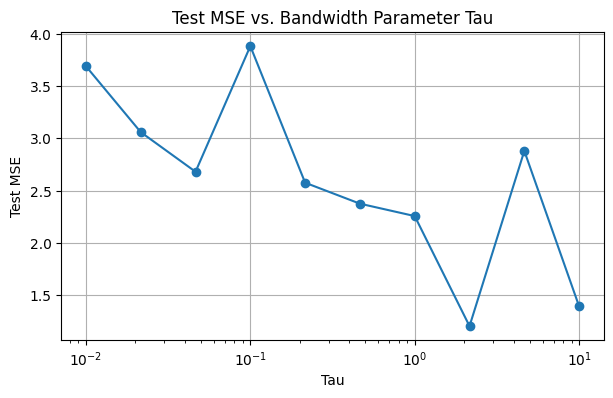

In [34]:
tau_values = np.logspace(-2, 1, 10)  # Creates 10 values between 0.01 and 10

best_tau = None
best_score = float('inf')  # Assuming lower score is better, e.g., lower MSE

mse_scores = []
for tau in tau_values:
    y_pred_test = predict_lwlr(
        X_train,
        y_train,
        X_test,
        alpha,
        tau,
        iterations
    )

    mse = mean_squared_error(
        y_test,
        y_pred_test
    )

    mse_scores.append(mse)

    # Update the best Tau
    if mse < best_score:
        best_score = mse
        best_tau = tau

# Update the best Tau
print(f"Best tau: {best_tau}")
print(f"Minimum Test MSE: {best_score}")

# Plot the MSE values against Tau values
plt.figure(figsize=(7, 4))

plt.semilogx(
    tau_values,
    mse_scores,
    marker='o'
)

plt.xlabel('Tau')
plt.ylabel('Test MSE')
plt.title('Test MSE vs. Bandwidth Parameter Tau')
plt.grid(True)

plt.show()

### Part F: Analysis
Discuss how different $τ$ values influence the model’s flexibility and fitting capacity.

The bandwidth parameter ($\tau$) controls how strongly Locally Weighted Linear Regression focuses on training examples close to the query point. A small ($\tau$) causes the weights to decrease rapidly with distance, so the model focuses mainly on nearby points. This makes the model more flexible and capable of capturing local patterns, but it can also cause overfitting because it relies on very few observations.

A large ($\tau$) causes the weights to decrease more slowly, meaning that more training examples have significant influence on the prediction. This produces a smoother and less flexible model and can reduce overfitting, but if ($\tau$) is too large, the model may fail to capture local patterns and behave similarly to standard linear regression.

Therefore, the optimal ($\tau$) provides a balance between flexibility and generalization. In this experiment, the best value is the ($\tau$) that produces the lowest test MSE.